# Seminar 9. Linear Programming as the Foundation of Integer Optimization

Checks for the corners of an LP, the simplex tableaux, duality and shadow prices.

## 1. Setup

Every numerical data leaf is compared with an independent calculation.

In [1]:
import copy
import difflib
import io
import itertools
import json
import logging
import math
import random
import re
import zlib
from datetime import date, datetime, time, timedelta, timezone
from decimal import ROUND_HALF_UP, Decimal
from fractions import Fraction as Fr
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from scipy.optimize import linprog

SEED = 42
TOPIC = "Linear Programming as the Foundation of Integer Optimization"
SEMINAR = "09"
NOTEBOOK = f"{SEMINAR}. {TOPIC}.ipynb"


def find_author_root(start):
    """The folder Seminars/Evgeny Baulin, searched from start upwards."""
    for base in (start, *start.parents):
        for cand in (base, base / "Seminars" / "Evgeny Baulin"):
            if (cand / "checks" / NOTEBOOK).is_file():
                return cand
    raise FileNotFoundError(f"Seminars/Evgeny Baulin/checks/{NOTEBOOK} not found above {start}")


AUTHOR = find_author_root(Path.cwd())
ROOT = AUTHOR.parents[1]
NB_PATH = AUTHOR / "checks" / NOTEBOOK
THEORY = AUTHOR / "theory" / f"{SEMINAR}. {TOPIC}"
CONTENT = THEORY / "content"
FIG_DIR = THEORY / "figures"
WEB = AUTHOR / "web" / SEMINAR
CONTENT_FILES = [WEB / "js" / f"content-{name}.js"
                 for name in ("ui", "main", "problems", "handout", "cheatsheet")]
np.set_printoptions(precision=6, suppress=True)


def strict_loads(text, name):
    """JSON without NaN, Infinity or repeated keys."""
    def pairs(items):
        keys = [k for k, _ in items]
        if len(keys) != len(set(keys)):
            raise ValueError(f"{name}: a repeated key among {keys}")
        return dict(items)

    def constant(value):
        raise ValueError(f"{name}: {value} is not JSON")

    return json.loads(text, object_pairs_hook=pairs, parse_constant=constant)


def strict_json(path):
    return strict_loads(path.read_text(encoding="utf-8"), path.name)


def marked_json(path):
    """The JSON between /*JSON-BEGIN*/ and /*JSON-END*/ of a content file, and the text around it."""
    text = path.read_text(encoding="utf-8")
    m = re.search(r"/\*JSON-BEGIN\*/(.*)/\*JSON-END\*/", text, re.S)
    if m is None:
        raise ValueError(f"{path.name}: no JSON markers")
    return strict_loads(m.group(1), path.name), text[:m.start()] + text[m.end():]


def write_if_changed(path, content):
    """Write text or bytes only when they differ from the file; True when written."""
    content = content.encode("utf-8") if isinstance(content, str) else content
    if path.is_file() and path.read_bytes() == content:
        return False
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_bytes(content)
    return True


PUBLIC = strict_json(CONTENT / "public.json")
PUBLIC["content"] = {k: v for path in CONTENT_FILES for k, v in marked_json(path)[0].items()}
STUDENTS = strict_json(CONTENT / "students.json")
PUB, STU = PUBLIC["data"], STUDENTS["data"]
CHECKS = []
COVERED = set()
MISSING = object()


def short(value, width=40):
    if isinstance(value, np.ndarray):
        value = value.tolist()
    if isinstance(value, (list, tuple)):
        text = "[" + ", ".join(short(v, 10**6) for v in value) + "]"
    elif isinstance(value, dict):
        text = "{" + ", ".join(f"{k}: {short(v, 10**6)}" for k, v in value.items()) + "}"
    elif isinstance(value, (float, np.floating)):
        text = f"{float(value):.10g}"
    else:
        text = str(value)
    return text if len(text) <= width else text[:width - 3] + "..."


def same(computed, expected, tol):
    if isinstance(expected, np.ndarray):
        expected = expected.tolist()
    if isinstance(expected, bool):
        return isinstance(computed, (bool, np.bool_)) and bool(computed) == expected
    if isinstance(expected, str):
        return isinstance(computed, str) and computed == expected
    if isinstance(expected, dict):
        return (isinstance(computed, dict) and list(computed) == list(expected)
                and all(same(computed[k], expected[k], tol) for k in expected))
    if isinstance(expected, (list, tuple)):
        return (isinstance(computed, (list, tuple, np.ndarray)) and len(computed) == len(expected)
                and all(same(c, e, tol) for c, e in zip(computed, expected)))
    if expected is None or computed is None or isinstance(computed, (bool, np.bool_, str, dict, list)):
        return False
    c, e = float(computed), float(expected)
    return math.isfinite(c) and abs(c - e) <= tol


def check(name, computed, expected, tol=1e-12):
    """Numbers within tol (absolute); strings, booleans, lists and dicts entry by entry."""
    passed = same(computed, expected, tol)
    CHECKS.append({"check": name, "computed": short(computed), "expected": short(expected),
                   "detail": short(computed, 600), "passed": passed})
    return passed


def section(prefix):
    """The checks whose names start with prefix, one line each."""
    rows = [c for c in CHECKS if c["check"].startswith(prefix + ":")]
    if not rows:
        return
    width = max(len(c["check"]) for c in rows)
    for c in rows:
        tail = "ok" if c["passed"] else f"FAILED, expected {c['expected']}"
        print(f"{c['check']:<{width}}  {c['computed']:<40}  {tail}")


def at(root, path):
    """The node at a dotted path, list entries counted from 1."""
    node = root
    for part in path.split("."):
        if isinstance(node, dict) and part in node:
            node = node[part]
        elif isinstance(node, list) and part.isdigit() and 1 <= int(part) <= len(node):
            node = node[int(part) - 1]
        else:
            return MISSING
    return node


def leaves(node, path):
    if isinstance(node, dict):
        for k, v in node.items():
            yield from leaves(v, f"{path}.{k}")
    elif isinstance(node, list):
        for i, v in enumerate(node, start=1):
            yield from leaves(v, f"{path}.{i}")
    else:
        yield path


def nodes(node):
    if isinstance(node, dict):
        yield node
        for v in node.values():
            yield from nodes(v)
    elif isinstance(node, list):
        for v in node:
            yield from nodes(v)


def lookup(path):
    """(file, node) for a data path that sits in exactly one of the two data sections."""
    found = [(name, at(root, path)) for name, root in (("public", PUB), ("students", STU))]
    found = [(name, node) for name, node in found if node is not MISSING]
    return found[0] if len(found) == 1 else (None, MISSING)


def group(path):
    head, *rest = path.split(".")
    return {"answers": rest[0] if rest else head, "zero": "0", "release": "timeline"}.get(head, head)


def expect(path, computed, tol=1e-9):
    """Compare a computed value with the data leaf at path and mark the leaf as checked."""
    name, expected = lookup(path)
    if expected is MISSING:
        return check(f"{group(path)}: {path} (missing in the data)", computed, None)
    COVERED.update((name, p) for p in leaves(expected, path))
    return check(f"{group(path)}: {path}", computed, expected, tol)


def expect_answer(path, computed):
    """Answer spec: the computed value, and a tolerance that takes 4 significant digits but not 1% off."""
    pid, key = path.split(".")
    name, spec = lookup(f"answers.{path}")
    if spec is MISSING:
        return check(f"{pid}: answer {key} (missing in the data)", computed, None)
    COVERED.update((name, p) for p in leaves(spec, f"answers.{path}"))
    value, tol = spec.get("value"), spec.get("tol")
    typed = float(f"{float(computed):.4g}")

    def accepted(a):
        return abs(a - value) <= tol * max(1, abs(value))

    check(f"{pid}: answer {key} is a number spec", [sorted(spec), spec.get("type")],
          [["tol", "type", "value"], "number"])
    check(f"{pid}: answer {key} equals the computed value", abs(value - float(computed)), 0.0,
          max(tol, 1e-4 * max(1, abs(float(computed)))))
    check(f"{pid}: answer {key}: the tolerance accepts {typed:g}", accepted(typed), True)
    # When the tolerance is a sizeable fraction of the value, the 1% rejection test is uninformative.
    if abs(value) > 1e-6 and tol < 0.005 * abs(value):
        check(f"{pid}: answer {key}: the tolerance rejects a 1% error",
              not accepted(float(computed) * 1.01) and not accepted(float(computed) * 0.99), True)


print(f"numpy {np.__version__} | matplotlib {matplotlib.__version__} | seed {SEED}")
print(f"notebook: {NB_PATH.relative_to(ROOT)}")
print(f"data leaves: {len(list(leaves(PUB, 'p')))} public, {len(list(leaves(STU, 's')))} students")

numpy 2.5.2 | matplotlib 3.11.1 | seed 42
notebook: Seminars/Evgeny Baulin/checks/09. Linear Programming as the Foundation of Integer Optimization.ipynb
data leaves: 323 public, 157 students


## 2. Helpers

A tableau comes straight from its basis through $B^{-1}$, not from pivoting; corners come from all basic solutions; `linprog` is the numerical cross-check.

In [2]:
def tex_entry(v):
    v = sp.Rational(v)
    return str(v.p) if v.q == 1 else f"{float(v):g}"


def tableau(full, b, cost, basis):
    """Rows B^-1 [A | b] and the last row c_B B^-1 A - c, straight from the basis, without pivoting."""
    A_, b_, c_ = sp.Matrix(full), sp.Matrix(b), sp.Matrix(cost)
    Binv = A_[:, list(basis)].inv()
    body, rhs = Binv * A_, Binv * b_
    cb = sp.Matrix([cost[j] for j in basis])
    rows = [list(body.row(i)) + [rhs[i]] for i in range(len(basis))]
    rows.append(list(cb.T * body - c_.T) + [(cb.T * rhs)[0]])
    return rows


def next_pivot(rows):
    """Most negative entry of the last row, smallest ratio; None at the optimum."""
    z = rows[-1][:-1]
    e = min(range(len(z)), key=lambda j: (z[j], j))
    if z[e] >= 0:
        return None
    ratios = {i: row[-1] / row[e] for i, row in enumerate(rows[:-1]) if row[e] > 0}
    return min(ratios, key=lambda i: (ratios[i], i)), e, list(ratios.values())


def tableau_tex(rows, labels, names, zname="z", pivot=None):
    head = " & " + " & ".join(names) + " & \\\\ \\hline"
    lines = []
    for i, row in enumerate(rows):
        cells = [tex_entry(v) for v in row]
        if pivot is not None and i == pivot[0]:
            cells[pivot[1]] = "\\boxed{" + cells[pivot[1]] + "}"
        line = (labels[i] if i < len(labels) else zname) + " & " + " & ".join(cells) + " \\\\"
        lines.append(line + (" \\hline" if i == len(labels) - 1 else ""))
    body = " ".join(lines)[:-3]
    return "\\begin{array}{c|" + "c" * len(names) + "|c} " + head + " " + body + " \\end{array}"


def walk(full, b, cost, basis, names, zname="z"):
    """Tableau strings, ratio lists and objective values along the path of the most negative rule."""
    basis = list(basis)
    texts, ratios, values, bases = [], [], [], [list(basis)]
    while True:
        rows = tableau(full, b, cost, basis)
        step = next_pivot(rows)
        labels = [names[j] for j in basis]
        texts.append(tableau_tex(rows, labels, names, zname, None if step is None else step[:2]))
        values.append(rows[-1][-1])
        if step is None:
            return texts, ratios, values, bases, rows
        r, e, rs = step
        ratios.append(rs)
        basis[r] = e
        bases.append(list(basis))


def basic_solutions(full, b):
    """Every choice of m columns: (columns, None) when singular, else (columns, the solution)."""
    m, n = len(full), len(full[0])
    A_, b_ = sp.Matrix(full), sp.Matrix(b)
    out = []
    for cols in itertools.combinations(range(n), m):
        B = A_[:, list(cols)]
        if B.det() == 0:
            out.append((cols, None))
            continue
        v = [sp.Integer(0)] * n
        for j, val in zip(cols, B.solve(b_)):
            v[j] = val
        out.append((cols, v))
    return out


def with_slacks(A):
    m = len(A)
    return [list(row) + [int(i == k) for k in range(m)] for i, row in enumerate(A)]


def corners(A, b):
    """The corners of Ax <= b, x >= 0, sorted, in the original variables."""
    n = len(A[0])
    pts = {tuple(v[:n]) for _, v in basic_solutions(with_slacks(A), b) if v is not None and all(t >= 0 for t in v)}
    return sorted(pts)


def best_corner(A, b, c):
    pts = corners(A, b)
    return max(pts, key=lambda p: sum(ci * pi for ci, pi in zip(c, p)))


def value(c, x):
    return sum(ci * xi for ci, xi in zip(c, x))


def solve_max(A, b, c):
    """linprog as the numerical cross-check: the point, the value and the prices of the maximization."""
    res = linprog([-v for v in c], A_ub=A, b_ub=b, method="highs")
    return res.x, -res.fun, -res.ineqlin.marginals


def lin(coefs, names):
    out = ""
    for a, n in zip(coefs, names):
        if a:
            out += ("-" if a < 0 else "+" if out else "") + ("" if abs(a) == 1 else str(abs(a))) + n
    return out


def statement_has(pid, pieces):
    """The rows typed into a statement against the parameters, in both languages."""
    text = PUBLIC["content"]["problems"][pid]["statement"]
    check(f"{pid}: the statement carries the parameters",
          [(lang, p) for lang in ("en", "ru") for p in pieces if p not in text[lang]], [])


def erratum_has(pid, piece):
    text = PUBLIC["content"]["problems"][pid]["erratum"]
    check(f"{pid}: the erratum names its number", [lang for lang in ("en", "ru") if piece not in text[lang]], [])

## 3. The problems

### A1. A feed blend

$\min\,5x+4y$ s.t. $2x+y\ge8$, $x+3y\ge9$, $x,y\ge0$; all six basic solutions.

In [3]:
P = PUB["A1"]["params"]
cost, A, b = P["cost"], P["A"], P["b"]
names = ["x", "y", "s_1", "s_2"]
full = [A[0] + [-1, 0], A[1] + [0, -1]]
rows = basic_solutions(full, b)
feasible = [(cols, v) for cols, v in rows if v is not None and all(t >= 0 for t in v)]
points = sorted({tuple(v[:2]) for _, v in feasible}, key=lambda p: p[0])
values = [value(cost, p) for p in points]
best = min(points, key=lambda p: value(cost, p))

lines = []
for cols, v in rows:
    ok = all(t >= 0 for t in v)
    tail = "\\checkmark & " + tex_entry(value(cost, v[:2])) if ok else "\\times & "
    lines.append(",".join(names[j] for j in cols) + " & " + " & ".join(tex_entry(t) for t in v) + " & " + tail + " \\\\")
table = ("\\begin{array}{c|cccc|c|c} B & x & y & s_1 & s_2 & \\ge 0 & z \\\\ \\hline "
         + " ".join(lines)[:-3] + " \\end{array}")

expect("A1.params", {"cost": cost, "A": A, "b": b})
expect("A1.vertices", [list(p) for p in points])
expect("A1.zv", values)
expect("A1.x", list(best))
expect("A1.z", value(cost, best))
expect("A1.nBasic", len(rows))
expect("A1.nFeasible", len(feasible))
expect("A1.table", table)
lp = linprog(cost, A_ub=[[-v for v in r] for r in A], b_ub=[-v for v in b])
check("A1: linprog agrees", [*lp.x, lp.fun], [float(v) for v in best] + [float(value(cost, best))], 1e-9)

expect_answer("A1.x", best[0])
expect_answer("A1.z", value(cost, best))
expect_answer("A1.count", len(feasible))
section("A1")

A1: A1.params                                       {cost: [5, 4], A: [[2, 1], [1, 3]], b...  ok
A1: A1.vertices                                     [[0, 8], [3, 2], [9, 0]]                  ok
A1: A1.zv                                           [32, 23, 45]                              ok
A1: A1.x                                            [3, 2]                                    ok
A1: A1.z                                            23                                        ok
A1: A1.nBasic                                       6                                         ok
A1: A1.nFeasible                                    3                                         ok
A1: A1.table                                        \begin{array}{c|cccc|c|c} B & x & y &...  ok
A1: linprog agrees                                  [3, 2, 23]                                ok
A1: answer x is a number spec                       [[tol, type, value], number]              ok
A1: answer x equals the comput

### A2. All the basic solutions

Three slacks, five columns, ten choices of which one is singular.

In [4]:
P = PUB["A2"]["params"]
c, A, b = P["c"], P["A"], P["b"]
xy = ["x", "y"]


def a2(b):
    rows = basic_solutions(with_slacks(A), b)
    ok = [v for _, v in rows if v is not None and all(t >= 0 for t in v)]
    star = best_corner(A, b, c)
    return rows, ok, star


rows, ok, star = a2(b)
order = [[0, 0], [5, 0], [5, 2], [4, 3], [0, 5]]
expect("A2.params", {"c": c, "A": A, "b": b})
statement_has("A2", [lin(c, xy), lin(A[0], xy) + rf"\le{b[0]}", lin(A[1], xy) + r"\le{{A2.params.b.2}}",
                     lin(A[2], xy) + rf"\le{b[2]}"])
expect("A2.nChoices", len(rows))
expect("A2.nBasic", sum(v is not None for _, v in rows))
expect("A2.nFeasible", len(ok))
check("A2: the listed corners are the corners", sorted(map(tuple, order)), corners(A, b))
expect("A2.vertices", order)
expect("A2.zv", [value(c, p) for p in order])
expect("A2.x", list(star))
expect("A2.z", value(c, star))
check("A2: the singular choice is {y, s1, s2}", [cols for cols, v in rows if v is None], [(1, 2, 3)])
check("A2: linprog agrees", solve_max(A, b, c)[1], float(value(c, star)), 1e-9)

E_ = PUB["A2"]["err"]
b_e = [E_["b"], *b[1:]]
_, ok_e, star_e = a2(b_e)
expect("A2.err.b", E_["b"])
erratum_has("A2", r"x+y\le{{A2.err.b}}")
expect("A2.e", {"nFeasible": len(ok_e), "z": value(c, star_e), "x": list(star_e)})

expect_answer("A2.nBasic", sum(v is not None for _, v in rows))
expect_answer("A2.nFeasible", len(ok))
expect_answer("A2.z", value(c, star))
section("A2")

A2: A2.params                                           {c: [3, 2], A: [[1, 1], [1, 2], [1, 0...  ok
A2: the statement carries the parameters                []                                        ok
A2: A2.nChoices                                         10                                        ok
A2: A2.nBasic                                           9                                         ok
A2: A2.nFeasible                                        5                                         ok
A2: the listed corners are the corners                  [[0, 0], [0, 5], [4, 3], [5, 0], [5, 2]]  ok
A2: A2.vertices                                         [[0, 0], [5, 0], [5, 2], [4, 3], [0, 5]]  ok
A2: A2.zv                                               [0, 15, 19, 18, 10]                       ok
A2: A2.x                                                [5, 2]                                    ok
A2: A2.z                                                19                                 

### A3. A free variable

$\min\,x+2y$ s.t. $x+y\ge1$, $x\le6$, $y$ free.

In [5]:
P = PUB["A3"]["params"]
(c1, c2), b1, u = P["c"], P["b"], P["u"]
expect("A3.params", {"c": [c1, c2], "b": b1, "u": u})
statement_has("A3", [lin([c1, c2], ["x", "y"]), rf"x+y\ge{b1}", rf"x\le{u}"])


def a3(u):
    """Standard form in the variables x, y+, y-, s1, s2: the best basic feasible solution."""
    full = [[1, 1, -1, -1, 0], [1, 0, 0, 0, 1]]
    cost = [c1, c2, -c2, 0, 0]
    ok = [v for _, v in basic_solutions(full, [b1, u]) if v is not None and all(t >= 0 for t in v)]
    return len(full[0]), min(ok, key=lambda v: value(cost, v))


n, v = a3(u)
y_star = v[1] - v[2]
z_star = c1 * v[0] + c2 * y_star
lp = linprog([c1, c2], A_ub=[[-1, -1], [1, 0]], b_ub=[-b1, u], bounds=[(0, None), (None, None)])
check("A3: linprog agrees", [*lp.x, lp.fun], [float(v[0]), float(y_star), float(z_star)], 1e-9)
check("A3: y+ is zero at the optimum", v[1], 0)
expect("A3.n", n)
expect("A3.x", v[0])
expect("A3.y", y_star)
expect("A3.ym", v[2])
expect("A3.z", z_star)

u_e = PUB["A3"]["err"]["u"]
_, v_e = a3(u_e)
expect("A3.err.u", u_e)
erratum_has("A3", r"x\le{{A3.err.u}}")
expect("A3.e", {"y": v_e[1] - v_e[2], "z": c1 * v_e[0] + c2 * (v_e[1] - v_e[2])})

expect_answer("A3.n", n)
expect_answer("A3.y", y_star)
expect_answer("A3.z", z_star)
section("A3")

A3: A3.params                                   {c: [1, 2], b: 1, u: 6}                   ok
A3: the statement carries the parameters        []                                        ok
A3: linprog agrees                              [6, -5, -4]                               ok
A3: y+ is zero at the optimum                   0                                         ok
A3: A3.n                                        5                                         ok
A3: A3.x                                        6                                         ok
A3: A3.y                                        -5                                        ok
A3: A3.ym                                       5                                         ok
A3: A3.z                                        -4                                        ok
A3: A3.err.u                                    7                                         ok
A3: the erratum names its number                []                    

### B1. A bakery by tableau

$\max\,2x+5y$ under three rows; two pivots.

In [6]:
P = PUB["B1"]["params"]
c, A, b = P["c"], P["A"], P["b"]
xy = ["x", "y"]
names = ["x", "y", "s_1", "s_2", "s_3"]
full = with_slacks(A)
cost = c + [0, 0, 0]
texts, ratios, values, bases, last = walk(full, b, cost, [2, 3, 4], names)

path = []
for basis in bases:
    v = [sp.Integer(0)] * 5
    for j, val in zip(basis, sp.Matrix(full)[:, basis].solve(sp.Matrix(b))):
        v[j] = val
    path.append(v)
star = path[-1]

expect("B1.params", {"c": c, "A": A, "b": b})
statement_has("B1", [lin(A[i], xy) + rf"\le{{{{B1.params.b.{i + 1}}}}}" for i in range(3)])
expect("B1.t0", texts[0])
expect("B1.t1", texts[1])
expect("B1.t2", texts[2])
expect("B1.ratios1", ratios[0])
expect("B1.ratios2", ratios[1])
expect("B1.path", [p[:2] for p in path])
expect("B1.zPath", values)
expect("B1.x", star[:2])
expect("B1.z", values[-1])
expect("B1.slack", star[2:])
check("B1: two pivots", len(bases) - 1, 2)
check("B1: the best corner is the same", list(best_corner(A, b, c)), star[:2])
check("B1: linprog agrees", [*solve_max(A, b, c)[0], solve_max(A, b, c)[1]], [float(t) for t in star[:2]] + [float(values[-1])], 1e-9)

# the other way round: x enters first, then the walk follows the edges
others = [p for p in corners(A, b) if p[0] > star[0]]
expect("B1.other", [list(p) for p in sorted(others, reverse=True)])

expect_answer("B1.x", star[0])
expect_answer("B1.y", star[1])
expect_answer("B1.z", values[-1])
section("B1")

B1: B1.params                                   {c: [2, 5], A: [[1, 1], [2, 1], [0, 2...  ok
B1: the statement carries the parameters        []                                        ok
B1: B1.t0                                       \begin{array}{c|ccccc|c}  & x & y & s...  ok
B1: B1.t1                                       \begin{array}{c|ccccc|c}  & x & y & s...  ok
B1: B1.t2                                       \begin{array}{c|ccccc|c}  & x & y & s...  ok
B1: B1.ratios1                                  [8, 14, 5]                                ok
B1: B1.ratios2                                  [3, 9/2]                                  ok
B1: B1.path                                     [[0, 0], [0, 5], [3, 5]]                  ok
B1: B1.zPath                                    [0, 25, 31]                               ok
B1: B1.x                                        [3, 5]                                    ok
B1: B1.z                                        31                    

### B2. Three variables

$\max\,5x_1+4x_2+3x_3$.

In [7]:
P = PUB["B2"]["params"]
c, A, b = P["c"], P["A"], P["b"]
names3 = ["x_1", "x_2", "x_3"]
names = names3 + ["s_1", "s_2", "s_3"]
full = with_slacks(A)
cost = c + [0, 0, 0]


def b2(b):
    texts, ratios, values, bases, last = walk(full, b, cost, [3, 4, 5], names)
    v = [sp.Integer(0)] * 6
    for j, row in zip(bases[-1], last[:-1]):
        v[j] = row[-1]
    return texts, ratios, values, v


texts, ratios, values, v = b2(b)
expect("B2.params", {"c": c, "A": A, "b": b})
statement_has("B2", [lin(c, names3), lin(A[0], names3) + r"\le{{B2.params.b.1}}", lin(A[1], names3) + rf"\le{b[1]}",
                     lin(A[2], names3) + r"\le{{B2.params.b.3}}"])
expect("B2.t0", texts[0])
expect("B2.t1", texts[1])
expect("B2.t2", texts[2])
expect("B2.ratios1", ratios[0])
expect("B2.ratios2", ratios[1])
expect("B2.zPath", values)
expect("B2.x", v[:3])
expect("B2.s3", v[5])
expect("B2.z", values[-1])
x_num, z_num, _ = solve_max(A, b, c)
check("B2: linprog agrees", [*x_num, z_num], [float(t) for t in v[:3]] + [float(values[-1])], 1e-9)

b_e = PUB["B2"]["err"]["b"]
_, _, values_e, v_e = b2([b_e, *b[1:]])
expect("B2.err.b", b_e)
expect("B2.e", {"x3": v_e[2], "s3": v_e[5], "z": values_e[-1]})

expect_answer("B2.z", values[-1])
expect_answer("B2.x3", v[2])
expect_answer("B2.s3", v[5])
section("B2")

B2: B2.params                                    {c: [5, 4, 3], A: [[1, 0, 1], [1, 3, ...  ok
B2: the statement carries the parameters         []                                        ok
B2: B2.t0                                        \begin{array}{c|cccccc|c}  & x_1 & x_...  ok
B2: B2.t1                                        \begin{array}{c|cccccc|c}  & x_1 & x_...  ok
B2: B2.t2                                        \begin{array}{c|cccccc|c}  & x_1 & x_...  ok
B2: B2.ratios1                                   [14, 6, 13]                               ok
B2: B2.ratios2                                   [8, 14]                                   ok
B2: B2.zPath                                     [0, 30, 54]                               ok
B2: B2.x                                         [6, 0, 8]                                 ok
B2: B2.s3                                        6                                         ok
B2: B2.z                                         54         

### B3. Phase I

$\max\,2x+y$ s.t. $x+y\le6$, $x-y\ge2$; one artificial variable.

In [8]:
P = PUB["B3"]["params"]
c, A, b = P["c"], P["A"], P["b"]
names1 = ["x", "y", "s_1", "s_2", "a"]
names2 = names1[:4]
full1 = [A[0] + [1, 0, 0], A[1] + [0, -1, 1]]
full2 = [row[:4] for row in full1]
expect("B3.params", {"c": c, "A": A, "b": b})
statement_has("B3", [lin(c, ["x", "y"]), lin(A[0], ["x", "y"]) + rf"\le{b[0]}", lin(A[1], ["x", "y"]) + rf"\ge{b[1]}"])


def b3(b):
    phase1 = walk(full1, b, [0, 0, 0, 0, -1], [2, 4], names1, zname="-w")
    check("B3: Phase I ends with w = 0", phase1[2][-1], 0)
    basis = phase1[3][-1]
    phase2 = walk(full2, b, c + [0, 0], basis, names2)
    v = [sp.Integer(0)] * 4
    for j, row in zip(phase2[3][-1], phase2[4][:-1]):
        v[j] = row[-1]
    return phase1, phase2, v


phase1, phase2, v = b3(b)
start = [sp.Integer(0)] * 4
for j, row in zip(phase1[3][-1], phase1[4][:-1]):
    start[j] = row[-1]
mid = [sp.Integer(0)] * 4
for j, val in zip(phase2[3][1], sp.Matrix(full2)[:, phase2[3][1]].solve(sp.Matrix(b))):
    mid[j] = val

expect("B3.ta", phase1[0][0])
expect("B3.tb", phase1[0][1])
expect("B3.t0", phase2[0][0])
expect("B3.t1", phase2[0][1])
expect("B3.t2", phase2[0][2])
expect("B3.start", start[:2])
expect("B3.zStart", phase2[2][0])
expect("B3.mid", mid[:2])
expect("B3.zMid", phase2[2][1])
expect("B3.x", v[:2])
expect("B3.s2", v[3])
expect("B3.z", phase2[2][-1])
lp = linprog([-t for t in c], A_ub=[A[0], [-t for t in A[1]]], b_ub=[b[0], -b[1]])
check("B3: linprog agrees", [*lp.x, -lp.fun], [float(t) for t in v[:2]] + [float(phase2[2][-1])], 1e-9)

b_e = PUB["B3"]["err"]["b"]
_, phase2_e, v_e = b3([b_e, b[1]])
expect("B3.err.b", b_e)
erratum_has("B3", r"x+y\le{{B3.err.b}}")
expect("B3.e", {"z": phase2_e[2][-1], "s2": v_e[3]})

expect_answer("B3.xStart", start[0])
expect_answer("B3.z", phase2[2][-1])
expect_answer("B3.s2", v[3])
section("B3")

B3: B3.params                                        {c: [2, 1], A: [[1, 1], [1, -1]], b: ...  ok
B3: the statement carries the parameters             []                                        ok
B3: Phase I ends with w = 0                          0                                         ok
B3: B3.ta                                            \begin{array}{c|ccccc|c}  & x & y & s...  ok
B3: B3.tb                                            \begin{array}{c|ccccc|c}  & x & y & s...  ok
B3: B3.t0                                            \begin{array}{c|cccc|c}  & x & y & s_...  ok
B3: B3.t1                                            \begin{array}{c|cccc|c}  & x & y & s_...  ok
B3: B3.t2                                            \begin{array}{c|cccc|c}  & x & y & s_...  ok
B3: B3.start                                         [2, 0]                                    ok
B3: B3.zStart                                        4                                         ok
B3: B3.mid          

### C1. The price of oven time

The dual of B1 from complementary slackness, and $p^*(b_1)$.

In [9]:
P = PUB["B1"]["params"]
c, A, b = P["c"], P["A"], P["b"]
full = with_slacks(A)
star = [sp.Integer(t) for t in PUB["B1"]["x"]]
slack = [b[i] - value(A[i], star) for i in range(3)]

# complementary slackness: y2 = 0 on the slack row, both dual rows tight
y1, y2, y3 = sp.symbols("y1 y2 y3")
ys = [y1, y2, y3]
eqs = [yi for yi, s in zip(ys, slack) if s != 0]
eqs += [sum(A[i][j] * ys[i] for i in range(3)) - c[j] for j in range(2) if star[j] > 0]
sol = sp.solve(eqs, ys, dict=True)[0]
y = [sol[v] for v in ys]
basis = [0, 3, 1]
last = tableau(full, b, c + [0, 0, 0], basis)
check("C1: the prices stand in the last row under the slacks", last[-1][2:5], y)
expect("C1.y", y)
expect("C1.w", value(b, y))
check("C1: strong duality", value(b, y), value(c, star))
check("C1: linprog marginals agree", solve_max(A, b, c)[2], [float(t) for t in y], 1e-9)
check("C1: the dual as its own LP agrees",
      linprog(b, A_ub=[[-A[i][j] for i in range(3)] for j in range(2)], b_ub=[-t for t in c]).fun, float(value(b, y)), 1e-9)

# delta on b1 moves the basic variables by the column of s1
col = [row[2] for row in last[:-1]]
vals = [row[-1] for row in last[:-1]]
lo = max(-v / d for v, d in zip(vals, col) if d > 0)
hi = min(-v / d for v, d in zip(vals, col) if d < 0)
expect("C1.delta", [lo, hi])
expect("C1.range", [b[0] + lo, b[0] + hi])


def p_star(b1):
    return value(c, best_corner(A, [b1, b[1], b[2]], c))


br = [sp.Integer(0), b[0] + lo, b[0] + hi]
slopes = [(p_star(br[1]) - p_star(br[0])) / (br[1] - br[0]), (p_star(br[2]) - p_star(br[1])) / (br[2] - br[1]),
          p_star(br[2] + 1) - p_star(br[2])]
expect("C1.pb", {"breaks": br, "values": [p_star(t) for t in br], "slopes": slopes})
check("C1: the middle slope is the price", slopes[1], y[0])
check("C1: p* is linear between the kinks",
      [p_star(br[0] + (br[1] - br[0]) / 2), p_star(br[1] + (br[2] - br[1]) / 2)],
      [(p_star(br[0]) + p_star(br[1])) / 2, (p_star(br[1]) + p_star(br[2])) / 2])
check("C1: the slopes fall", bool(slopes[0] > slopes[1] > slopes[2]), True)

expect_answer("C1.y1", y[0])
expect_answer("C1.y3", y[2])
expect_answer("C1.ub", b[0] + hi)
section("C1")

C1: the prices stand in the last row under the slacks  [2, 0, 3/2]                               ok
C1: C1.y                                               [2, 0, 3/2]                               ok
C1: C1.w                                               31                                        ok
C1: strong duality                                     31                                        ok
C1: linprog marginals agree                            [2, 0, 1.5]                               ok
C1: the dual as its own LP agrees                      31                                        ok
C1: C1.delta                                           [-3, 3/2]                                 ok
C1: C1.range                                           [5, 19/2]                                 ok
C1: C1.pb                                              {breaks: [0, 5, 19/2], values: [0, 25...  ok
C1: the middle slope is the price                      2                                         ok


### C2. Solving the dual

Three variables, two rows: the dual is a picture.

In [10]:
P = PUB["C2"]["params"]
c, A, b = P["c"], P["A"], P["b"]
names3 = ["x_1", "x_2", "x_3"]
expect("C2.params", {"c": c, "A": A, "b": b})
statement_has("C2", [r"9x_1+{{C2.params.c.2}}x_2+3x_3", lin(A[0], names3) + r"\le{{C2.params.b.1}}",
                     lin(A[1], names3) + r"\le{{C2.params.b.2}}"])
check("C2: the objective typed in the statement", [c[0], c[2]], [9, 3])


def dual_corners():
    """The corners of A^T y >= c, y >= 0: every pair of its five lines."""
    rows = [([A[0][j], A[1][j]], c[j]) for j in range(3)] + [([1, 0], 0), ([0, 1], 0)]
    out = set()
    for (r1, s1), (r2, s2) in itertools.combinations(rows, 2):
        M = sp.Matrix([r1, r2])
        if M.det() == 0:
            continue
        p = tuple(M.solve(sp.Matrix([s1, s2])))
        if all(r[0] * p[0] + r[1] * p[1] >= s for r, s in rows):
            out.add(p)
    return sorted(out)


def c2(b):
    pts = dual_corners()
    ys = min(pts, key=lambda p: value(b, p))
    # third dual row slack: x3 = 0; both y positive: both primal rows tight
    check("C2: the third dual row is slack and both prices are positive",
          [bool(A[0][2] * ys[0] + A[1][2] * ys[1] > c[2]), bool(ys[0] > 0), bool(ys[1] > 0)], [True, True, True])
    x12 = sp.Matrix([A[0][:2], A[1][:2]]).solve(sp.Matrix(b))
    return pts, ys, [x12[0], x12[1], 0]


pts, ys, x = c2(b)
expect("C2.dualV", [list(p) for p in pts])
expect("C2.dualZ", [value(b, p) for p in pts])
expect("C2.y", list(ys))
expect("C2.w", value(b, ys))
expect("C2.x", x)
check("C2: both values agree", value(c, x), value(b, ys))
x_num, z_num, y_num = solve_max(A, b, c)
check("C2: linprog agrees", [*x_num, z_num, *y_num], [*map(float, x), float(value(b, ys)), *map(float, ys)], 1e-9)

b_e = PUB["C2"]["err"]["b"]
_, ys_e, x_e = c2([b[0], b_e])
expect("C2.err.b", b_e)
check("C2: the footnote keeps the prices", ys_e, ys)
expect("C2.e", {"w": value([b[0], b_e], ys_e), "x1": x_e[0]})

expect_answer("C2.y1", ys[0])
expect_answer("C2.w", value(b, ys))
expect_answer("C2.x1", x[0])
section("C2")

C2: C2.params                                                 {c: [9, 10, 3], A: [[2, 2, 5], [3, 4,...  ok
C2: the statement carries the parameters                      []                                        ok
C2: the objective typed in the statement                      [9, 3]                                    ok
C2: the third dual row is slack and both prices are positive  [True, True, True]                        ok
C2: C2.dualV                                                  [[0, 3], [3, 1], [5, 0]]                  ok
C2: C2.dualZ                                                  [72, 66, 70]                              ok
C2: C2.y                                                      [3, 1]                                    ok
C2: C2.w                                                      66                                        ok
C2: C2.x                                                      [4, 3, 0]                                 ok
C2: both values agree                

### C3. Ranges

The third row is slack and still limits the range of $b_1$.

In [11]:
P = PUB["C3"]["params"]
c, A, b = P["c"], P["A"], P["b"]
xy = ["x", "y"]
expect("C3.params", {"c": c, "A": A, "b": b})
statement_has("C3", [lin(c, xy), lin(A[0], xy) + rf"\le{b[0]}", lin(A[1], xy) + r"\le{{C3.params.b.2}}",
                     lin(A[2], xy) + rf"\le{b[2]}"])
full = with_slacks(A)


def c3(b):
    star = best_corner(A, b, c)
    basis = [0, 1, 4]
    last = tableau(full, b, c + [0, 0, 0], basis)
    check("C3: the basis x, y, s3 is optimal", all(bool(t >= 0) for t in last[-1][:-1]), True)
    col = [row[2] for row in last[:-1]]
    vals = [row[-1] for row in last[:-1]]
    return star, last, min(-v / d for v, d in zip(vals, col) if d < 0)


star, last, dub = c3(b)
expect("C3.x", list(star))
expect("C3.z", value(c, star))
expect("C3.slack", b[2] - value(A[2], star))
expect("C3.y", last[-1][2:5])
expect("C3.dub", dub)
expect("C3.ub", b[0] + dub)
check("C3: linprog marginals agree", solve_max(A, b, c)[2], [float(t) for t in last[-1][2:5]], 1e-9)
check("C3: past the limit the slope falls",
      bool(value(c, best_corner(A, [b[0] + dub + 1, *b[1:]], c)) - value(c, star) < last[-1][2] * (dub + 1)), True)

# the coefficient of x: the point must beat every other corner
t = sp.symbols("t")
lows, highs = [], []
for p in corners(A, b):
    if p == star:
        continue
    d0, d1 = star[0] - p[0], star[1] - p[1]
    edge = -c[1] * d1 / sp.Integer(d0) if d0 != 0 else None
    if d0 > 0:
        lows.append(edge)
    elif d0 < 0:
        highs.append(edge)
cr = [max(lows), min(highs)]
expect("C3.cr", cr)

b_e = PUB["C3"]["err"]["b"]
star_e, last_e, dub_e = c3([b[0], b_e, b[2]])
expect("C3.err.b", b_e)
erratum_has("C3", r"2x+y\le{{C3.err.b}}")
check("C3: the footnote keeps the prices", last_e[-1][2:5], last[-1][2:5])
expect("C3.e", {"x": list(star_e), "z": value(c, star_e), "ub": b[0] + dub_e})

expect_answer("C3.y1", last[-1][2])
expect_answer("C3.ub", b[0] + dub)
expect_answer("C3.cu", cr[1])
section("C3")

C3: C3.params                                    {c: [4, 3], A: [[1, 1], [2, 1], [0, 1...  ok
C3: the statement carries the parameters         []                                        ok
C3: the basis x, y, s3 is optimal                True                                      ok
C3: C3.x                                         [5, 4]                                    ok
C3: C3.z                                         32                                        ok
C3: C3.slack                                     2                                         ok
C3: C3.y                                         [2, 1, 0]                                 ok
C3: C3.dub                                       1                                         ok
C3: C3.ub                                        10                                        ok
C3: linprog marginals agree                      [2, 1, 0]                                 ok
C3: past the limit the slope falls               True       

## 4. Exit ticket and block D

In [12]:
E = PUB["exit"]
expect("exit.m", E["m"])
expect("exit.n", E["n"])
expect("exit.low", E["low"])
expect("exit.high", E["high"])
expect("exit.price", Fr(E["price"]).limit_denominator(100))
expect("exit.db", Fr(E["db"]).limit_denominator(100))
expect("exit.basics", math.comb(E["n"], E["m"]))
expect("exit.gap", E["high"] - E["low"])
expect("exit.change", Fr(E["price"]).limit_denominator(100) * Fr(E["db"]).limit_denominator(100))


def pivots(T, basis, rule, limit=2000):
    """Tableau rows over Fractions; the status, the pivot count, the last rows and the cycle length."""
    T, basis, seen = [row[:] for row in T], list(basis), {tuple(basis): 0}
    m = len(basis)
    for k in range(1, limit):
        z = T[-1][:-1]
        neg = [j for j, v in enumerate(z) if v < 0]
        if not neg:
            return "optimal", k - 1, T, None
        e = neg[0] if rule == "bland" else min(neg, key=lambda j: (z[j], j))
        ratios = {i: T[i][-1] / T[i][e] for i in range(m) if T[i][e] > 0}
        if not ratios:
            return "unbounded", k - 1, T, None
        r = min(ratios, key=lambda i: (ratios[i], basis[i]))
        T[r] = [v / T[r][e] for v in T[r]]
        for i in range(m + 1):
            if i != r:
                T[i] = [a - T[i][e] * p for a, p in zip(T[i], T[r])]
        basis[r] = e
        if tuple(basis) in seen:
            return "cycle", k, T, k - seen[tuple(basis)]
        seen[tuple(basis)] = k
    return "limit", limit, T, None


def start_rows(A, b, c):
    m = len(A)
    T = [[Fr(v) for v in A[i]] + [Fr(int(i == k)) for k in range(m)] + [Fr(b[i])] for i in range(m)]
    return T + [[-Fr(v) for v in c] + [Fr(0)] * (m + 1)]


# D1: one pivot, then a column with a negative z-entry and nothing positive
D = PUB["demo"]["unb"]
names = ["x", "y", "s_1", "s_2"]
texts = tableau(with_slacks(D["A"]), D["b"], D["c"] + [0, 0], [0, 3])
check("demo: D1 the column of y stops nothing", [bool(texts[-1][1] < 0), all(bool(r[1] <= 0) for r in texts[:-1])], [True, True])
res = linprog([-v for v in D["c"]], A_ub=D["A"], b_ub=D["b"])
expect("demo.unb", {"c": D["c"], "A": D["A"], "b": D["b"], "t1": tableau_tex(texts, ["x", "s_2"], names), "status": res.status})

# D2: Phase I stops with a positive artificial; the certificate adds the rows
D = PUB["demo"]["inf"]
lo_, hi_ = D["b"]
ph1 = linprog([0, 0, 1], A_ub=[[1, 1, 0], [-1, -1, -1]], b_ub=[lo_, -hi_])
res = linprog([-1, -1], A_ub=[[1, 1], [-1, -1]], b_ub=[lo_, -hi_])
expect("demo.inf", {"b": [lo_, hi_], "a": ph1.fun, "sum": lo_ - hi_, "status": res.status}, 1e-9)

# D3: Beale's example cycles under the most negative rule, not under Bland's
D = PUB["demo"]["cycle"]
to_fr = lambda v: Fr(v).limit_denominator(100)
A_c, b_c, c_c = [[to_fr(v) for v in r] for r in D["A"]], [to_fr(v) for v in D["b"]], [to_fr(v) for v in D["c"]]
T0 = start_rows(A_c, b_c, [-v for v in c_c])
st_d, k_d, T_d, period = pivots(T0, [4, 5, 6], "dantzig")
st_b, k_b, T_b, _ = pivots(T0, [4, 5, 6], "bland")
check("demo: D3 the most negative rule cycles at z = 0", [st_d, T_d[-1][-1]], ["cycle", 0])
check("demo: D3 Bland's rule stops", st_b, "optimal")
res = linprog(D["c"], A_ub=D["A"], b_ub=D["b"])
expect("demo.cycle", {"c": c_c, "A": A_c, "b": b_c, "period": period, "bland": k_b, "opt": -T_b[-1][-1]})
check("demo: D3 linprog agrees", res.fun, -float(T_b[-1][-1]), 1e-9)


# D4: Klee-Minty against random problems of the same sizes
def klee_minty(n):
    A = [[2 ** (i - j + 1) if j < i else int(j == i) for j in range(n)] for i in range(n)]
    return A, [5 ** (i + 1) for i in range(n)], [2 ** (n - 1 - j) for j in range(n)]


ns = PUB["demo"]["km"]["ns"]
km, rng, rand = [], random.Random(9), []
for n in ns:
    A, b, c = klee_minty(n)
    st, k, T, _ = pivots(start_rows(A, b, c), range(n, 2 * n), "dantzig")
    check(f"demo: D4 Klee-Minty n = {n} ends at 5^n", [st, T[-1][-1]], ["optimal", 5 ** n])
    km.append(k)
    total = 0
    for _ in range(40):
        A = [[rng.randint(1, 9) for _ in range(n)] for _ in range(n)]
        b = [rng.randint(20, 60) for _ in range(n)]
        c = [rng.randint(1, 9) for _ in range(n)]
        st, k, T, _ = pivots(start_rows(A, b, c), range(n, 2 * n), "dantzig")
        total += k
    check(f"demo: D4 the last random problem of n = {n} agrees with linprog", float(T[-1][-1]), solve_max(A, b, c)[1], 1e-7)
    rand.append(total / 40)
check("demo: D4 all 2^n corners", km, [2 ** n - 1 for n in ns])
shown = [2, 4, 6, 8]
expect("demo.km", {"ns": ns, "pivots": km, "random": rand, "shownN": shown, "shownP": [km[i - 1] for i in shown],
                   "shownR": [rand[i - 1] for i in shown]})
section("exit")
section("demo")

exit: exit.m       3                                         ok
exit: exit.n       6                                         ok
exit: exit.low     17                                        ok
exit: exit.high    19                                        ok
exit: exit.price   5/2                                       ok
exit: exit.db      2/5                                       ok
exit: exit.basics  20                                        ok
exit: exit.gap     2                                         ok
exit: exit.change  1                                         ok
demo: D1 the column of y stops nothing                         [True, True]                              ok
demo: demo.unb                                                 {c: [1, 1], A: [[1, -1], [-1, 1]], b:...  ok
demo: demo.inf                                                 {b: [2, 4], a: 2, sum: -2, status: 2}     ok
demo: D3 the most negative rule cycles at z = 0                [cycle, 0]                           

## 5. Release and timeline

Start at 13:00 Moscow time; the planned lengths add up to the end of the class at 14:20.

In [13]:
PLAN = {
    "0": [("recap", 6)],
    "A": [("recap", 2), ("P1", 5), ("P23", 6), ("review", 2)],
    "B": [("recap", 2), ("P1", 7), ("P23", 9), ("review", 3)],
    "C": [("recap", 2), ("P1", 6), ("P23", 7), ("review", 3)],
    "D": [("D1", Fr(5, 2)), ("D2", Fr(5, 2)), ("D3", Fr(5, 2)), ("D4", Fr(5, 2))],
    "E": [("summary", 2), ("exit", 2), ("home", 1)],
}
START = 13 * 60


def mmss(minutes):
    seconds = int(minutes * 60)
    return f"{seconds // 60}:{seconds % 60:02d}"


def clock_str(minutes):
    minute = START + int(minutes)
    return f"{minute // 60}:{minute % 60:02d}"


timeline = {"blocks": list(PLAN), "sec": {}, "start": {}, "clock": {}}
elapsed = 0
for block, parts in PLAN.items():
    total = sum(m for _, m in parts)
    timeline[block] = {key: mmss(m) for key, m in parts}
    timeline[block]["total"] = mmss(total)
    timeline["sec"][block] = {key: int(m * 60) for key, m in parts}
    timeline["start"][block] = mmss(elapsed)
    timeline["clock"][block] = clock_str(elapsed)
    elapsed += total

timeline["buffer"] = mmss(5)
timeline["sec"]["buffer"] = 300
timeline["start"]["buffer"] = mmss(elapsed)
timeline["clock"]["buffer"] = clock_str(elapsed)
timeline["total"] = mmss(elapsed + 5)
timeline["clock"]["end"] = clock_str(elapsed + 5)
expect("timeline", timeline)
check("timeline: the class lasts 80 minutes with the buffer", elapsed + 5, 80)

MONTHS_RU = ["января", "февраля", "марта", "апреля", "мая", "июня", "июля", "августа", "сентября",
             "октября", "ноября", "декабря"]
day = date(2026, 11, 9)
release = datetime.combine(day, time(14, 20), timezone(timedelta(hours=3)))
expect("release.iso", release.isoformat())
expect("release.day", f"{day.day} {day.strftime('%B')}")
expect("release.dayRu", f"{day.day} {MONTHS_RU[day.month - 1]}")
check("timeline: release is on Monday", day.weekday(), 0)
check("timeline: the class ends at the release time", timeline["clock"]["end"], release.strftime("%H:%M"))
check("timeline: config matches the release",
      re.findall(r"unlockAt:\s*'([^']*)'", (WEB / "js/config.js").read_text()), [release.isoformat()])
section("timeline")

all_leaves = [(name, p) for name, data in [("public", PUB), ("students", STU)]
              for key, value in data.items() for p in leaves(value, key)]
check("coverage: every data leaf has an independent calculation", sorted(set(all_leaves) - COVERED), [])
print(f"{len(COVERED)} data leaves checked")

timeline: timeline                                    {blocks: [0, A, B, C, D, E], sec: {0:...  ok
timeline: the class lasts 80 minutes with the buffer  80                                        ok
timeline: release.iso                                 2026-11-09T14:20:00+03:00                 ok
timeline: release.day                                 9 November                                ok
timeline: release.dayRu                               9 ноября                                  ok
timeline: release is on Monday                        0                                         ok
timeline: the class ends at the release time          14:20                                     ok
timeline: config matches the release                  [2026-11-09T14:20:00+03:00]               ok
480 data leaves checked


## 6. Figures

The blend, the simplex path, $p^*(b_1)$ and the pivot counts of block D.

In [14]:
failed = [c["check"] for c in CHECKS if not c["passed"]]
assert not failed, f"figures refused, failed checks: {failed}"

logging.getLogger("fontTools").setLevel(logging.ERROR)

HSE = {
    "blue": "#102D69",
    "accent": "#C62828",
    "gray": "#6C727E",
    "orange": "#C96A00",
    "light": "#EBEFF6",
    "fill": "#C9D6EA",
    "fill2": "#F3D4D4",
}
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["STIXGeneral"],
    "mathtext.fontset": "stix",
    "font.size": 12,
    "axes.edgecolor": HSE["gray"],
    "axes.linewidth": 0.8,
    "xtick.color": HSE["gray"],
    "ytick.color": HSE["gray"],
    "svg.hashsalt": "seminar09",
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
})
FIGURES = []
PUBLIC_FIGURES = {d["src"] for d in nodes(PUBLIC["content"]) if isinstance(d.get("src"), str)}
SERIF = "font-family: 'STIXGeneral', 'STIX Two Text', 'Times New Roman', Times, serif"


def save(fig, name):
    """Write name.svg and name.pdf for the handout, and name.svg for a public figure."""
    buffer = io.BytesIO()
    fig.savefig(buffer, format="svg", bbox_inches="tight", metadata={"Date": None})
    svg = re.sub(r"font-family: 'STIXGeneral'(, serif)?(?=[;\"])", SERIF, buffer.getvalue().decode("utf-8"))
    buffer = io.BytesIO()
    fig.savefig(buffer, format="pdf", bbox_inches="tight", metadata={"CreationDate": None, "ModDate": None})
    targets = {FIG_DIR / f"{name}.svg": svg.encode("utf-8"), FIG_DIR / f"{name}.pdf": buffer.getvalue()}
    if name in PUBLIC_FIGURES:
        targets[WEB / "figures" / f"{name}.svg"] = svg.encode("utf-8")
    for path, content in targets.items():
        write_if_changed(path, content)
    words = [t.get_text() for t in fig.findobj(matplotlib.text.Text)
             if re.search("[A-Za-z]", re.sub(r"\$[^$]*\$", "", t.get_text()))]
    check(f"figures: {name} has no words outside formulas", words, [])
    if name not in FIGURES:
        FIGURES.append(name)

### fig_a1: the blend and its basic solutions

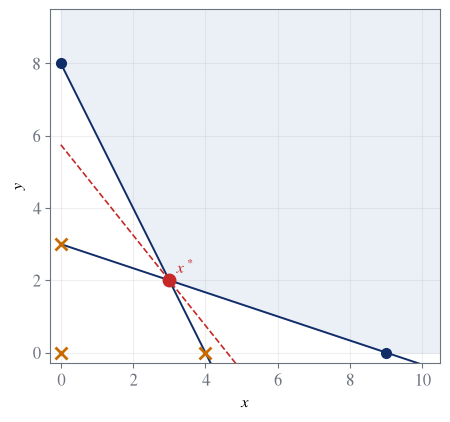

In [15]:
a1 = PUB["A1"]
(a11, a12), (a21, a22) = a1["params"]["A"]
b1, b2 = a1["params"]["b"]
fig, ax = plt.subplots(figsize=(6.0, 4.6))
t = np.linspace(0, 11, 400)
top = np.full_like(t, 10.0)
low = np.maximum.reduce([(b1 - a11 * t) / a12, (b2 - a21 * t) / a22, 0 * t])
ax.fill_between(t, low, top, color=HSE["light"], zorder=0)
ax.plot(t, (b1 - a11 * t) / a12, color=HSE["blue"], lw=1.4)
ax.plot(t, (b2 - a21 * t) / a22, color=HSE["blue"], lw=1.4)
c1_, c2_ = a1["params"]["cost"]
ax.plot(t, (a1["z"] - c1_ * t) / c2_, "--", color=HSE["accent"], lw=1.2)
V = np.array(a1["vertices"])
ax.plot(V[:, 0], V[:, 1], "o", color=HSE["blue"], ms=7, zorder=4)
for p in [(b1 / a11, 0), (0, b2 / a22), (0, 0)]:
    ax.plot(*p, "x", color=HSE["orange"], ms=9, mew=2, zorder=5, clip_on=False)
ax.plot(*a1["x"], "o", color=HSE["accent"], ms=9, zorder=5)
ax.text(a1["x"][0] + 0.2, a1["x"][1] + 0.2, r"$x^*$", color=HSE["accent"])
ax.set(xlim=(-0.3, 10.5), ylim=(-0.3, 9.5), xlabel=r"$x$", ylabel=r"$y$", aspect="equal")
ax.grid(alpha=0.2)
save(fig, "fig_a1")
plt.show()

### fig_b1: the path of the simplex method

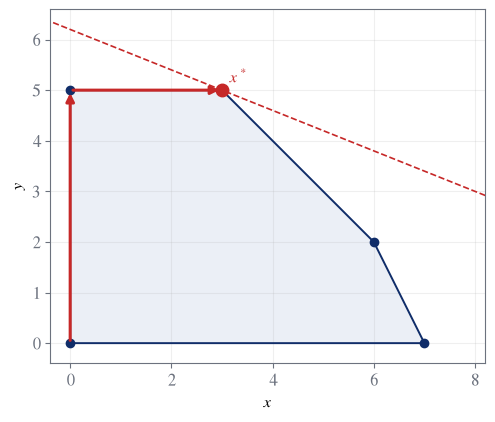

In [16]:
b1_ = PUB["B1"]
A_, b_, c_ = b1_["params"]["A"], b1_["params"]["b"], b1_["params"]["c"]
pts = [[0, 0], b1_["other"][0], b1_["other"][1], b1_["x"], b1_["path"][1]]
V = np.array(pts, dtype=float)
fig, ax = plt.subplots(figsize=(6.0, 4.6))
ax.fill(V[:, 0], V[:, 1], color=HSE["light"], zorder=0)
ax.plot(np.append(V[:, 0], V[0, 0]), np.append(V[:, 1], V[0, 1]), color=HSE["blue"], lw=1.4)
t = np.linspace(-0.5, 8.5, 2)
ax.plot(t, (b1_["z"] - c_[0] * t) / c_[1], "--", color=HSE["accent"], lw=1.2)
path = np.array(b1_["path"], dtype=float)
for p, q in zip(path[:-1], path[1:]):
    ax.annotate("", xy=q, xytext=p, zorder=6, arrowprops={"arrowstyle": "-|>", "color": HSE["accent"], "lw": 2.2})
ax.plot(V[:, 0], V[:, 1], "o", color=HSE["blue"], ms=6, zorder=4)
ax.plot(*b1_["x"], "o", color=HSE["accent"], ms=9, zorder=5)
ax.text(b1_["x"][0] + 0.15, b1_["x"][1] + 0.15, r"$x^*$", color=HSE["accent"])
ax.set(xlim=(-0.4, 8.2), ylim=(-0.4, 6.6), xlabel=r"$x$", ylabel=r"$y$", aspect="equal")
ax.grid(alpha=0.2)
save(fig, "fig_b1")
plt.show()

### fig_c1: the optimal value against the oven limit

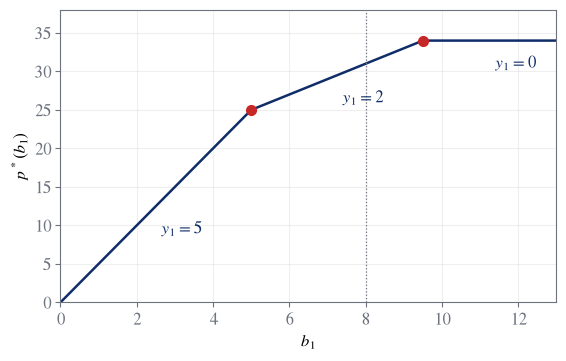

In [17]:
pb = PUB["C1"]["pb"]
br, vals, sl = pb["breaks"], pb["values"], pb["slopes"]
xs = [*br, br[-1] + 3.5]
ys = [*vals, vals[-1]]
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot(xs, ys, "-", color=HSE["blue"], lw=1.8)
ax.plot(br[1:], vals[1:], "o", color=HSE["accent"], ms=7, zorder=4)
ax.axvline(PUB["B1"]["params"]["b"][0], color=HSE["gray"], lw=0.9, ls=":")
for i, s in enumerate(sl):
    mx, my = (xs[i] + xs[i + 1]) / 2, (ys[i] + ys[i + 1]) / 2
    ax.text(mx + 0.15, my - 3.6, rf"$y_1={s:g}$", color=HSE["blue"])
ax.set(xlim=(0, xs[-1]), ylim=(0, 38), xlabel=r"$b_1$", ylabel=r"$p^*(b_1)$")
ax.grid(alpha=0.2)
save(fig, "fig_c1")
plt.show()

### fig_km: pivots on Klee-Minty and on random problems

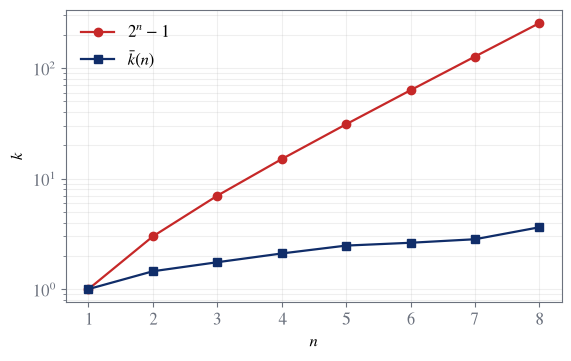

In [18]:
km_ = PUB["demo"]["km"]
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.semilogy(km_["ns"], km_["pivots"], "o-", color=HSE["accent"], lw=1.6, label=r"$2^n-1$")
ax.semilogy(km_["ns"], km_["random"], "s-", color=HSE["blue"], lw=1.6, label=r"$\bar k(n)$")
ax.set(xlabel=r"$n$", ylabel=r"$k$")
ax.legend(frameon=False)
ax.grid(alpha=0.2, which="both")
save(fig, "fig_km")
plt.show()

## 7. Handout and cheat sheet

LaTeX for both languages is built from the content files; the token substitutions and the formatting follow render.js so the printed numbers equal those on the page.

In [19]:
TOKEN = re.compile(r"\{\{\s*([A-Za-z0-9.]+)\s*\}\}")


def merge_over(target, overlay):
    """The merge of access.js: objects key by key, arrays element by element, anything else replaced."""
    for key, b in overlay.items():
        a = target.get(key)
        if isinstance(a, dict) and isinstance(b, dict):
            merge_over(a, b)
        elif isinstance(a, list) and isinstance(b, list):
            for i, item in enumerate(b):
                if i < len(a) and isinstance(a[i], dict) and isinstance(item, dict):
                    merge_over(a[i], item)
                elif i < len(a):
                    a[i] = copy.deepcopy(item)
                else:
                    a.append(copy.deepcopy(item))
        else:
            target[key] = copy.deepcopy(b)
    return target


def value_at(data, path):
    node = at(data, path)
    if node is MISSING or node is None or isinstance(node, dict):
        raise KeyError(f"unresolved token {path}")
    return node


def is_num(v):
    return isinstance(v, (int, float)) and not isinstance(v, bool)


def decimal_str(v, digits=4):
    s = str(Decimal(v).quantize(Decimal(1).scaleb(-digits), rounding=ROUND_HALF_UP))
    if "." in s:
        s = s.rstrip("0").rstrip(".")
    return "0" if s == "-0" else s


def tex_num(v, lang, math):
    s = decimal_str(v)
    if math:
        return s.replace(".", "{,}") if lang == "ru" else s
    s = s.replace(".", ",") if lang == "ru" else s
    return "−" + s[1:] if s.startswith("-") else s


def tex_value(v, lang, math):
    """render.value of render.js: a data value as TeX (math) or as text."""
    if is_num(v):
        return tex_num(v, lang, math)
    if isinstance(v, str):
        if math:
            return re.sub(r"(\d)\.(\d)", r"\1{,}\2", v).replace(r",\ ", r";\ ") if lang == "ru" else v
        if lang == "ru" and re.fullmatch(r"-?\d+\.\d+", v):
            v = v.replace(".", ",")
        return "−" + v[1:] if lang == "ru" and v.startswith("-") else v
    if isinstance(v, list) and v and all(is_num(x) for x in v):
        sep = (r";\ " if lang == "ru" else r",\ ") if math else ("; " if lang == "ru" else ", ")
        return "(" + sep.join(tex_num(x, lang, math) for x in v) + ")"
    if isinstance(v, list) and v and all(isinstance(r, list) and r and all(is_num(x) for x in r) for r in v):
        if not math:
            return " ".join(tex_value(r, lang, False) for r in v)
        rows = r" \\ ".join(" & ".join(tex_num(x, lang, True) for x in r) for r in v)
        return r"\begin{pmatrix} " + rows + r" \end{pmatrix}"
    return None


def tex_token(path, data, lang, math):
    v = value_at(data, path)
    tex = tex_value(v, lang, True)
    assert tex is not None, path
    if math:
        return tex
    text = tex_value(v, lang, False)
    return text if re.fullmatch(r"[0-9.,]+", text) else "$" + tex + "$"


def tex_segments(s):
    r"""The segmenter of render.js: $$display$$, $inline$, \$ a literal dollar, text; a lone $ is text."""
    out, buf, i = [], "", 0
    while i < len(s):
        ch = s[i]
        if ch == "\\" and s[i + 1 : i + 2] == "$":
            buf += "\x03"
            i += 2
            continue
        if ch == "$":
            display = s[i + 1 : i + 2] == "$"
            n = 2 if display else 1
            close = s.find("$$" if display else "$", i + n)
            if close < 0:
                buf += s[i:]
                break
            if buf:
                out.append(("text", buf))
            buf = ""
            out.append(("display" if display else "math", s[i + n : close]))
            i = close + n
            continue
        buf += ch
        i += 1
    if buf:
        out.append(("text", buf))
    return out


ESC = [("{", r"\{"), ("}", r"\}"), ("%", r"\%"), ("&", r"\&"), ("#", r"\#"), ("_", r"\_"),
       ("~", r"\textasciitilde{}"), ("^", r"\textasciicircum{}")]


def esc(text):
    text = text.replace("\\", "\x00")
    for a, b in ESC:
        text = text.replace(a, b)
    return text.replace("\x00", r"\textbackslash{}")


def rich(s, data, lang):
    """One content string as LaTeX: tokens become numbers and markup goes to \\textbf, \\emph, \\texttt."""
    segs = []
    for kind, seg in tex_segments(s):
        if kind == "display" and len(segs) > 1 and segs[-2][0] == "display" and segs[-1][0] == "text" \
                and not segs[-1][1].strip():
            segs.pop()
        if kind == "display" and segs and segs[-1][0] == "display":
            segs[-1][1].append(seg)
        else:
            segs.append((kind, [seg] if kind == "display" else seg))
    parts = []
    for kind, seg in segs:
        if kind == "display":
            lines = " \\\\[6pt]\n".join(b.strip() for b in seg)
            seg = lines if len(seg) == 1 else "\\begin{gathered}\n" + lines + "\n\\end{gathered}"
        if kind in ("math", "display"):
            body = TOKEN.sub(lambda m: tex_token(m.group(1), data, lang, True), seg)
            body = body.replace(" ", " ").replace(" ", r"\,")
            assert "%" not in body and "#" not in body and "{{" not in body, seg
            display = "\n\\handoutdisplay{\n" + body.strip() + "\n}\n"
            parts.append("$" + body + "$" if kind == "math" else display)
            continue
        toks, codes = [], []
        t = TOKEN.sub(lambda m: toks.append(m.group(1)) or f"\x01{len(toks) - 1}\x01", seg)
        t = re.sub(r"`([^`]+)`", lambda m: codes.append(esc(m.group(1))) or f"\x02{len(codes) - 1}\x02", t)
        t = esc(t).replace("\x03", r"\$").replace(" ", "~").replace(" ", r"\,")
        t = re.sub(r"\*\*([^*]+)\*\*", r"\\textbf{\1}", t)
        t = re.sub(r"\*([^*\s][^*]*)\*", r"\\emph{\1}", t)
        t = re.sub("\x02(\\d+)\x02", lambda m: r"\texttt{" + codes[int(m.group(1))] + "}", t)
        t = re.sub("\x01(\\d+)\x01", lambda m: tex_token(toks[int(m.group(1))], data, lang, False), t)
        parts.append(t)
    out = "".join(parts)
    assert not re.search("[\x00-\x03 ]", out), s
    return out


def tr(pair, data, lang, inline=False):
    """A pair as LaTeX; a missing Russian half falls back to the English half with English hyphenation."""
    if pair.get(lang):
        return rich(pair[lang], data, lang)
    tex = rich(pair["en"], data, "en")
    if lang == "en":
        return tex
    return "\\textenglish{" + tex + "}" if inline else "\\begin{english}\n" + tex + "\n\\end{english}"


FIG_WIDTH = {"fig_a1": 0.62, "fig_b1": 0.62, "fig_c1": 0.72, "fig_km": 0.72}
LABELS = {
    "en": {"course": "Optimization Methods", "seminar": "Seminar 09", "page": "Theory handout",
           "topic": "Linear Programming as the Foundation of Integer Optimization",
           "institution": "HSE University, Faculty of Computer Science", "year": "Academic year 2026-2027",
           "lecturer": "Course lecturer: Andrey Ignatov", "author": "Evgeny Baulin",
           "byline": "Author: Evgeny Baulin", "license": "MIT License", "kicker": "Seminar 09 cheat sheet",
           "definition": "Definition", "theorem": "Theorem", "lemma": "Lemma", "corollary": "Corollary",
           "proposition": "Proposition", "proof": "Proof", "example": "Example", "intuition": "Why",
           "trap": "Trap", "selfcheck": "Check yourself", "answer": "Answer", "convention": "Notation",
           "figure": "Figure", "statement": "Statement", "solution": "Solution",
           "board": "On the board", "students": "On your own"},
    "ru": {"course": "Методы оптимизации", "seminar": "Семинар 9", "page": "Конспект теории",
           "topic": "Линейное программирование как основа целочисленной оптимизации",
           "institution": "НИУ ВШЭ, факультет компьютерных наук", "year": "2026-2027 учебный год",
           "lecturer": "Лектор курса: Андрей Игнатов", "author": "Евгений Баулин",
           "byline": "Автор: Евгений Баулин", "license": "Лицензия MIT", "kicker": "Шпаргалка к семинару 9",
           "definition": "Определение", "theorem": "Теорема", "lemma": "Лемма", "corollary": "Следствие",
           "proposition": "Утверждение", "proof": "Доказательство", "example": "Пример",
           "intuition": "Почему", "trap": "Ловушка", "selfcheck": "Проверьте себя", "answer": "Ответ",
           "convention": "Обозначения", "figure": "Рисунок", "statement": "Условие", "solution": "Решение",
           "board": "У доски", "students": "Самостоятельно"},
}


def period(s):
    return s if s.endswith((".", "?", "!")) else s + "."


def block_tex(b, content, data, lang):
    t, L = b["type"], LABELS[lang]
    text = lambda pair: tr(pair, data, lang)
    title = lambda pair: tr(pair, data, lang, inline=True)
    if t == "p":
        return text(b["text"])
    if t in ("example", "intuition"):
        env = "examplebox" if t == "example" else "whybox"
        return f"\\begin{{{env}}}\n{text(b['text'])}\n\\end{{{env}}}"
    if t == "list":
        items = "\n".join("  \\item " + text(i) for i in b["items"])
        return "\\begin{itemize}\n" + items + "\n\\end{itemize}"
    if t == "figure":
        name = re.fullmatch(r"(?:figures/)?(fig_[a-z0-9_]+)(?:\.svg)?", b["src"]).group(1)
        cap = text(b["caption"]) if b.get("caption") else ""
        return f"\\handoutfigure{{{FIG_WIDTH[name]:g}}}{{{name}}}{{{cap}}}"
    if t in ("definition", "theorem"):
        kind = "definition" if t == "definition" else b.get("kind", "theorem")
        label = L[kind] + (": " + title(b["title"]) if b.get("title") else "")
        env = "definitionbox" if t == "definition" else "theorembox"
        return f"\\begin{{{env}}}{{{period(label)}}}\n{text(b['text'])}\n\\end{{{env}}}"
    if t in ("proof", "trap"):
        env = t + "box"
        return f"\\begin{{{env}}}\n{text(b['text'])}\n\\end{{{env}}}"
    if t == "note":
        return f"\\begin{{notebox}}{{{title(b['title'])}}}\n{text(b['text'])}\n\\end{{notebox}}"
    if t == "selfcheck":
        return (f"\\begin{{selfcheckbox}}\n{text(b['question'])}\n"
                f"\\selfcheckanswer {text(b['answer'])}\n\\end{{selfcheckbox}}")
    if t == "problem":
        return problem_tex(b["id"], content, data, lang)
    raise ValueError(f"unknown block type {t}")


def problem_tex(pid, content, data, lang):
    P, L = content["problems"][pid], LABELS[lang]
    steps = ["  \\item " + tr(st["text"], data, lang) for st in P["steps"]]
    return "\n".join([
        f"\\problemhead{{{pid}}}{{{tr(P['title'], data, lang, inline=True)}}}{{{L[P['who']]}}}",
        f"\\textbf{{{L['statement']}.}} {tr(P['statement'], data, lang)}",
        "",
        f"\\textbf{{{L['solution']}.}}",
        "\\begingroup\\sloppy",
        "\\begin{enumerate}[label=\\textbf{\\arabic*.}, leftmargin=*]",
        *steps,
        "\\end{enumerate}",
        "\\endgroup",
        "\\begin{answerbox}",
        tr(P["answerText"], data, lang),
        "\\end{answerbox}",
    ])


def fill(template, values):
    for name, tex in values.items():
        placeholder = f"<<{name}>>"
        assert template.count(placeholder) == 1, name
        template = template.replace(placeholder, tex)
    assert "<<" not in template
    return template


def tidy(doc):
    """No trailing spaces: a text segment before a display keeps the space it ended with."""
    return "\n".join(line.rstrip() for line in doc.split("\n"))

In [20]:
LANGUAGE_SETUP = {
    "en": r"""\usepackage{polyglossia}
\setdefaultlanguage{english}""",
    "ru": r"""\usepackage{polyglossia}
\setdefaultlanguage{russian}
\setotherlanguage{english}
\newfontfamily\cyrillicfont{cmunrm.otf}[Ligatures=TeX, BoldFont=cmunbx.otf, ItalicFont=cmunti.otf, BoldItalicFont=cmunbi.otf]
\newfontfamily\cyrillicfontsf{cmunss.otf}[Ligatures=TeX, BoldFont=cmunsx.otf, ItalicFont=cmunsi.otf, BoldItalicFont=cmunso.otf]
\newfontfamily\cyrillicfonttt{cmuntt.otf}[BoldFont=cmuntb.otf, ItalicFont=cmunit.otf, BoldItalicFont=cmuntx.otf]""",
}

THEORY_PREAMBLE = r"""% SPDX-License-Identifier: MIT
% Copyright (c) 2026 Evgeny Baulin
% Optimization Methods, Seminar 09: theory handout (<<language>>).
% Generated by checks/09. Linear Programming as the Foundation of Integer Optimization.ipynb from web/09/js/content-*.js and content/students.json. Do not edit by hand.
% Compile with: latexmk -xelatex -interaction=nonstopmode -halt-on-error <<file>>.tex
\documentclass[11pt,a4paper]{article}

\usepackage{fontspec}
\setmainfont{cmunrm.otf}[BoldFont=cmunbx.otf, ItalicFont=cmunti.otf, BoldItalicFont=cmunbi.otf]
\setsansfont{cmunss.otf}[BoldFont=cmunsx.otf, ItalicFont=cmunsi.otf, BoldItalicFont=cmunso.otf]
\setmonofont{cmuntt.otf}[BoldFont=cmuntb.otf, ItalicFont=cmunit.otf, BoldItalicFont=cmuntx.otf]
<<languageSetup>>

\usepackage[a4paper,left=2.3cm,right=2.3cm,top=2.4cm,bottom=2.4cm,headheight=14pt]{geometry}
\usepackage{amsmath,amssymb}
\usepackage{graphicx}
\usepackage{array,booktabs,longtable}
\usepackage{enumitem}
\usepackage{xcolor}
\usepackage[most]{tcolorbox}
\usepackage{titlesec}
\usepackage{fancyhdr}
\usepackage{needspace}
\usepackage[expansion=false]{microtype}
\usepackage[colorlinks=true,linkcolor=hseblue,urlcolor=hseblue,citecolor=hseblue]{hyperref}

\definecolor{hseblue}{RGB}{16,45,105}
\definecolor{hseaccent}{RGB}{198,40,40}
\definecolor{hsegray}{RGB}{108,114,126}
\definecolor{hselight}{RGB}{240,243,248}
\definecolor{hsewarm}{RGB}{253,244,232}

\hypersetup{pdftitle={<<pdftitle>>}, pdfauthor={<<pdfauthor>>}}

\titleformat{\section}{\color{hseblue}\Large\bfseries}{\thesection}{0.6em}{}
\titleformat{\subsection}{\color{hseblue}\large\bfseries}{\thesubsection}{0.6em}{}
\titlespacing*{\section}{0pt}{16pt plus 4pt minus 2pt}{8pt plus 2pt}
\titlespacing*{\subsection}{0pt}{12pt plus 3pt minus 2pt}{6pt plus 2pt}
\pretocmd{\section}{\Needspace{7\baselineskip}}{}{\errmessage{cannot patch section}}
\pretocmd{\subsection}{\Needspace{5\baselineskip}}{}{\errmessage{cannot patch subsection}}

\tcbset{handoutbox/.style={enhanced, breakable, sharp corners, boxrule=0pt, left=7pt, right=7pt, top=5pt, bottom=5pt, before skip=8pt plus 2pt, after skip=8pt plus 2pt}}
\newtcolorbox{examplebox}{handoutbox, colback=hselight, colframe=hselight, before upper={\textcolor{hseblue}{\bfseries <<labelExample>>}\ }}
\newtcolorbox{whybox}{handoutbox, colback=white, colframe=hseblue, leftrule=2.5pt, top=3pt, bottom=3pt, before upper={\textcolor{hseaccent}{\bfseries <<labelWhy>>}\ }}
\newtcolorbox{answerbox}{handoutbox, colback=hsewarm, colframe=hsewarm, before upper={\textcolor{hseaccent}{\bfseries <<labelAnswer>>}\ }}
\newtcolorbox{conventionbox}{handoutbox, colback=hselight, colframe=hseblue, leftrule=2.5pt, before upper={\textcolor{hseblue}{\bfseries <<labelConvention>>}\par\smallskip}}

\newcommand{\handoutfigure}[3]{\par\medskip\noindent\begin{minipage}{\linewidth}\centering
  \includegraphics[width=#1\linewidth]{figures/#2.pdf}\par\smallskip
  \begin{minipage}{0.94\linewidth}\small\textcolor{hseblue}{\bfseries <<labelFigure>>}\ #3\end{minipage}\end{minipage}\par\medskip}
\newcommand{\problemhead}[3]{\par\bigskip\noindent{\color{hseblue}\large\bfseries #1.\ #2}\par\nopagebreak
  \noindent{\small\itshape\color{hsegray}#3}\par\nopagebreak\smallskip}
\newtcolorbox{definitionbox}[1]{handoutbox, colback=white, colframe=hseblue, leftrule=2.5pt, before upper={\textcolor{hseblue}{\bfseries #1}\ }}
\newtcolorbox{theorembox}[1]{handoutbox, colback=hselight, colframe=hseblue, leftrule=2.5pt, before upper={\textcolor{hseblue}{\bfseries #1}\ }}
\newtcolorbox{proofbox}{handoutbox, colback=white, colframe=hsegray, leftrule=1.2pt, top=3pt, bottom=3pt, before upper={\textcolor{hsegray}{\bfseries\itshape <<labelProof>>}\ }}
\newtcolorbox{notebox}[1]{handoutbox, colback=hselight, colframe=hselight, before upper={\textcolor{hseblue}{\bfseries #1}\par\smallskip}}
\newtcolorbox{trapbox}{handoutbox, colback=hsewarm, colframe=hseaccent, leftrule=2.5pt, before upper={\textcolor{hseaccent}{\bfseries <<labelTrap>>}\ }}
\newtcolorbox{selfcheckbox}{handoutbox, colback=white, colframe=hseaccent, leftrule=2.5pt, top=3pt, bottom=3pt, before upper={\textcolor{hseaccent}{\bfseries <<labelSelfcheck>>}\ }}
\newcommand{\handoutdisplay}[1]{\sbox0{$\displaystyle #1$}\ifdim\wd0>\linewidth
  \par{\centering\binoppenalty=10000\relpenalty=0\relax$\displaystyle #1$\par}\else\[#1\]\fi}
\newcommand{\selfcheckanswer}{\par\smallskip\textcolor{hsegray}{\bfseries <<labelSelfcheckAnswer>>}\ }

\setlist[itemize]{itemsep=3pt,topsep=4pt}
\setlist[enumerate]{itemsep=3pt,topsep=4pt}
\setlength{\parindent}{0pt}
\setlength{\parskip}{5pt plus 1pt}
\setlength{\emergencystretch}{2em}
\setcounter{tocdepth}{2}

\pagestyle{fancy}
\fancyhf{}
\fancyhead[L]{\small\color{hsegray}<<headerCourse>>}
\fancyhead[R]{\small\color{hsegray}<<headerSeminar>>}
\fancyfoot[L]{\small\color{hsegray}<<footerAuthor>>}
\fancyfoot[C]{\small\thepage}
\fancyfoot[R]{\small\color{hsegray}<<footerLicense>>}
\renewcommand{\headrulewidth}{0pt}
\renewcommand{\footrulewidth}{0pt}
\fancypagestyle{plain}{\pagestyle{fancy}}

\begin{document}

\begin{center}
  {\large\color{hsegray}<<titleCourse>>\par}
  \vspace{4pt}
  {\large\bfseries\color{hseaccent}<<titleSeminar>>\par}
  \vspace{8pt}
  {\LARGE\bfseries\color{hseblue}<<titleTopic>>\par}
  \vspace{8pt}
  {\Large <<titlePage>>\par}
  \vspace{12pt}
  <<titleInstitution>>\par
  <<titleYear>>\par
  \vspace{8pt}
  <<titleLecturer>>\par
  <<titleAuthor>>\par
  Telegram: \href{https://t.me/tarakan_tuc}{@tarakan\_tuc}\par
\end{center}

\noindent{\color{hseblue}\rule{\linewidth}{0.6pt}}

\tableofcontents

\clearpage
"""

CHEAT_PREAMBLE = r"""% SPDX-License-Identifier: MIT
% Copyright (c) 2026 Evgeny Baulin
% Optimization Methods, Seminar 09: one-page cheat sheet (<<language>>).
% Generated by checks/09. Linear Programming as the Foundation of Integer Optimization.ipynb from web/09/js/content-cheatsheet.js and content/students.json. Do not edit by hand.
% Compile with: latexmk -xelatex -interaction=nonstopmode -halt-on-error <<file>>.tex
\RequirePackage{fix-cm}
\documentclass[10pt,a4paper]{article}

\usepackage{amsmath,amssymb}
\usepackage{fontspec}
\setmainfont{cmunrm.otf}[BoldFont=cmunbx.otf, ItalicFont=cmunti.otf, BoldItalicFont=cmunbi.otf]
\setsansfont{cmunss.otf}[BoldFont=cmunsx.otf, ItalicFont=cmunsi.otf, BoldItalicFont=cmunso.otf]
\setmonofont{cmuntt.otf}[BoldFont=cmuntb.otf, ItalicFont=cmunit.otf, BoldItalicFont=cmuntx.otf]
<<languageSetup>>

\usepackage[a4paper,left=8mm,right=8mm,top=7mm,bottom=11mm,footskip=5.5mm]{geometry}
\usepackage{xcolor}
\usepackage{multicol}
\usepackage{enumitem}
\usepackage{ragged2e}
\usepackage{fancyhdr}
\usepackage[colorlinks=true,linkcolor=hseblue,urlcolor=hseblue]{hyperref}

\definecolor{hseblue}{RGB}{16,45,105}
\definecolor{hseaccent}{RGB}{198,40,40}
\definecolor{hsegray}{RGB}{108,114,126}
\definecolor{hselight}{RGB}{240,243,248}

\hypersetup{pdftitle={<<pdftitle>>}, pdfauthor={<<pdfauthor>>}}

\pagestyle{fancy}
\fancyhf{}
\renewcommand{\headrulewidth}{0pt}
\fancyfoot[L]{\scriptsize\color{hsegray}\textcopyright\ 2026 <<footerAuthor>>, \href{https://t.me/tarakan_tuc}{t.me/tarakan\_tuc}}
\fancyfoot[R]{\scriptsize\color{hsegray}<<footerLicense>>}

\setlength{\parindent}{0pt}
\setlength{\parskip}{0pt}
\setlength{\columnsep}{4.5mm}
\setlength{\columnseprule}{0.3pt}
\renewcommand{\columnseprulecolor}{\color{hselight}}
\setlength{\emergencystretch}{2em}
\setlength{\RaggedRightRightskip}{0pt plus 4em}
\binoppenalty=2000
\relpenalty=500
\setlength{\abovedisplayskip}{2pt}
\setlength{\belowdisplayskip}{2pt}
\setlist[itemize]{leftmargin=7pt, labelsep=3pt, itemsep=1.2pt, topsep=1pt, parsep=0pt, partopsep=0pt,
  label={\color{hseaccent}\scriptsize\textbullet}}

\makeatletter
\newcommand{\cssec}[1]{\par\addvspace{3.5pt}\noindent
  \colorbox{hselight}{\parbox{\dimexpr\linewidth-2\fboxsep}{\RaggedRight\hyphenpenalty=10000\color{hseblue}\bfseries\strut #1}}%
  \par\nobreak\vspace{1pt}\@afterheading}
\makeatother
\clubpenalty=10000
\widowpenalty=10000

\begin{document}
\thispagestyle{fancy}

\noindent
\begin{minipage}[b]{0.6\textwidth}
  \RaggedRight\hyphenpenalty=10000
  {\color{hseaccent}\bfseries\small <<kicker>>}\\[1pt]
  {\color{hseblue}\bfseries\Large <<title>>}
\end{minipage}\hfill
\begin{minipage}[b]{0.39\textwidth}
  \raggedleft\footnotesize
  {\bfseries <<course>>}\\
  <<institution>>, 2026--2027\\
  <<lecturer>>\\
  <<byline>>, Telegram \href{https://t.me/tarakan_tuc}{@tarakan\_tuc}
\end{minipage}

\vspace{2pt}
{\color{hseblue}\rule{\textwidth}{0.8pt}}
\vspace{-4pt}

\fontsize{9}{<<leading>>}\selectfont
\begin{multicols}{3}
\RaggedRight
"""


def theory_tex(lang, content, data):
    h, L = content["handout"], LABELS[lang]
    topic = h["title"][lang] if h["title"].get(lang) else L["topic"]
    values = {
        "language": {"en": "English", "ru": "Russian"}[lang],
        "file": f"Theory_{lang}",
        "languageSetup": LANGUAGE_SETUP[lang],
        "pdftitle": esc(f"{L['course']}. {L['seminar']}. {L['page']}"),
        "pdfauthor": esc(L["author"]),
        "labelExample": period(L["example"]),
        "labelWhy": period(L["intuition"]),
        "labelAnswer": period(L["answer"]),
        "labelConvention": period(L["convention"]),
        "labelFigure": period(L["figure"]),
        "labelProof": period(L["proof"]),
        "labelTrap": period(L["trap"]),
        "labelSelfcheck": period(L["selfcheck"]),
        "labelSelfcheckAnswer": period(L["answer"]),
        "headerCourse": esc(L["course"]),
        "headerSeminar": esc(L["seminar"]),
        "footerAuthor": esc(L["author"]),
        "footerLicense": esc(L["license"]),
        "titleCourse": esc(L["course"]),
        "titleSeminar": esc(L["seminar"]),
        "titleTopic": rich(topic, data, lang),
        "titlePage": esc(L["page"]),
        "titleInstitution": esc(L["institution"]),
        "titleYear": esc(L["year"]),
        "titleLecturer": esc(L["lecturer"]),
        "titleAuthor": esc(L["author"]),
    }
    out = [fill(THEORY_PREAMBLE, values), "", tr(h["intro"], data, lang), "",
           "\\begin{conventionbox}", tr(h["convention"], data, lang), "\\end{conventionbox}", ""]
    for sec in h["sections"]:
        heading = tr(sec["title"], data, lang, inline=True)
        out += ["% " + "=" * 69, f"\\section{{{heading}}}\\label{{sec:{sec['id']}}}", ""]
        for b in sec.get("blocks", []):
            out += [block_tex(b, content, data, lang), ""]
        for sub in sec.get("subsections", []):
            heading = tr(sub["title"], data, lang, inline=True)
            out += [f"\\subsection{{{heading}}}\\label{{sub:{sub['id']}}}", ""]
            for b in sub.get("blocks", []):
                out += [block_tex(b, content, data, lang), ""]
    out.append("\\end{document}")
    return tidy("\n".join(out)) + "\n"


def split_title(title):
    """Two lines, broken at the space nearest to the middle that does not follow a short word."""
    spaces = [i for i, ch in enumerate(title) if ch == " " and len(title[:i].split(" ")[-1]) > 3]
    cut = min(spaces, key=lambda i: abs(i - len(title) / 2))
    return title[:cut] + "\\\\ " + title[cut + 1:]


def cheat_tex(lang, content, data):
    cs, L = content["cheatsheet"], LABELS[lang]
    hyphenation = "\n\\PolyglossiaSetup{russian}{hyphenmins={2,3}}" if lang == "ru" else ""
    values = {
        "language": {"en": "English", "ru": "Russian"}[lang],
        "file": f"Cheatsheet_{lang}",
        "languageSetup": LANGUAGE_SETUP[lang] + hyphenation,
        "pdftitle": esc(f"{L['kicker']}: {cs['title'][lang]}"),
        "pdfauthor": esc(L["author"]),
        "footerAuthor": esc(L["author"]),
        "footerLicense": esc(L["license"]),
        "kicker": esc(L["kicker"]),
        "title": split_title(tr(cs["title"], data, lang, inline=True)),
        "course": esc(L["course"]),
        "institution": esc(L["institution"]),
        "lecturer": esc(L["lecturer"]),
        "byline": esc(L["byline"]),
        "leading": {"en": "11.4", "ru": "10.6"}[lang],
    }
    out = [fill(CHEAT_PREAMBLE, values), ""]
    for sec in cs["sections"]:
        heading = tr(sec["title"], data, lang, inline=True)
        out += [f"% ---- {sec['id']}", f"\\cssec{{{heading}}}", "\\begin{itemize}"]
        out += ["  \\item " + tr(item, data, lang, inline=True) for item in sec["items"]]
        out += ["\\end{itemize}", ""]
    out += ["\\end{multicols}", "\\end{document}"]
    return tidy("\n".join(out)) + "\n"


def latex_sources(content, data):
    return {**{f"Theory_{lang}": theory_tex(lang, content, data) for lang in ("en", "ru")},
            **{f"Cheatsheet_{lang}": cheat_tex(lang, content, data) for lang in ("en", "ru")}}


assert sorted(FIG_WIDTH) == sorted(FIGURES), FIGURES
LATEX = latex_sources(merge_over(copy.deepcopy(PUBLIC["content"]), STUDENTS["content"]),
                      merge_over(copy.deepcopy(PUB), STU))
for name, text in LATEX.items():
    written = write_if_changed(THEORY / f"{name}.tex", text)
    print(f"{name}.tex: {text.count(chr(10))} lines, {'written' if written else 'unchanged'}")

Theory_en.tex: 459 lines, unchanged
Theory_ru.tex: 463 lines, unchanged
Cheatsheet_en.tex: 150 lines, unchanged
Cheatsheet_ru.tex: 155 lines, unchanged


## 8. Content consistency

Every visible string is an `{en, ru}` pair; every token resolves; no stray number or external URL leaks into the page or the handout.

In [21]:
REQUIRE_RU = True
CYR = re.compile("[\\u0400-\\u04FF]")
TELEGRAM = "https://t.me/tarakan_tuc"
NOT_TEXT = {"id", "who", "ref", "type", "kind", "src", "v", "keys", "pages"}
PROBLEM_IDS = ["A1", "A2", "A3", "B1", "B2", "B3", "C1", "C2", "C3"]
TEXT_SUFFIXES = {".html", ".css", ".js", ".json", ".svg", ".tex", ".txt", ".md", ".py", ".sh", ".ipynb",
                 ".service", ".timer"}


def visible(node, where, problems, untranslated):
    if isinstance(node, dict):
        if "en" in node or "ru" in node:
            if "en" not in node or not set(node) <= {"en", "ru"}:
                problems.append(f"{where}: keys {sorted(node)}")
            if "ru" not in node:
                untranslated.append(where)
            for lang in ("en", "ru"):
                if lang not in node:
                    continue
                if not isinstance(node[lang], str) or not node[lang].strip():
                    problems.append(f"{where}: empty or non-string '{lang}'")
                else:
                    yield where, lang, node[lang]
            return
        for k, v in node.items():
            yield from visible(v, f"{where}.{k}", problems, untranslated)
    elif isinstance(node, list):
        for i, v in enumerate(node):
            yield from visible(v, f"{where}[{i}]", problems, untranslated)
    elif isinstance(node, str) and where.rsplit(".", 1)[-1].split("[")[0] not in NOT_TEXT:
        problems.append(f"{where}: a bare string")


def cyrillic_outside_ru(node, where):
    if isinstance(node, dict):
        for k, v in node.items():
            if CYR.search(k):
                yield f"{where}: the key {k}"
            if (k == "ru" and "en" in node) or (where.startswith("data") and k.endswith("Ru")):
                continue
            yield from cyrillic_outside_ru(v, f"{where}.{k}")
    elif isinstance(node, list):
        for i, v in enumerate(node):
            yield from cyrillic_outside_ru(v, f"{where}[{i}]")
    elif isinstance(node, str) and CYR.search(node):
        yield where


def resolves(path, roots):
    return any(at(root, path) is not MISSING and not isinstance(at(root, path), dict) for root in roots)


def segments(text):
    out, buf, i = [], "", 0
    while i < len(text):
        if text[i] == "\\" and text[i + 1:i + 2] == "$":
            buf += "$"
            i += 2
            continue
        if text[i] == "$":
            display = text[i + 1:i + 2] == "$"
            width = 2 if display else 1
            close = text.find("$$" if display else "$", i + width)
            if close < 0:
                return None
            if buf:
                out.append(("text", buf))
            buf = ""
            out.append(("display" if display else "math", text[i + width:close]))
            i = close + width
            continue
        buf += text[i]
        i += 1
    if buf:
        out.append(("text", buf))
    return out


def stray_digits(kind, piece):
    piece = TOKEN.sub("", piece)
    if kind == "text":
        piece = re.sub(r"\b[A-Z]\d\b", "", piece)
        piece = re.sub(r"\b[Tt]asks? \d+(?:(?:, | and | to |-)\d+)*", "", piece)
        piece = re.sub(r"\b[Зз]адач\w*\s\d+(?:(?:,\s|\sи\s|\sдо\s|-)\d+)*", "", piece)
        piece = re.sub(r"\b[Ss]eminars?\s\d+(?:(?:, | and | to |-)\d+)*", "", piece)
        piece = re.sub(r"\b[Сс]еминар\w*\s\d+(?:(?:,\s|\sи\s|\sдо\s|-)\d+)*", "", piece)
        piece = re.sub(r"\b202[67]\b", "", piece)
        return [m for m in re.findall(r"\d+(?:\.\d+)?", piece) if m not in {"0", "1", "2", SEMINAR, SEMINAR[1]}]
    return [m for m in re.findall(r"\d+(?:\.\d+)?", piece) if len(m) > 1]


def pdf_pages(path):
    raw = Path(path).read_bytes()
    blobs = [raw]
    for m in re.finditer(rb"stream\r?\n(.*?)\r?\nendstream", raw, re.S):
        try:
            blobs.append(zlib.decompressobj().decompress(m.group(1)))
        except zlib.error:
            pass
    counts = []
    for b in blobs:
        for d in re.findall(rb"<<(?:[^<>]|<<[^<>]*>>)*?/Type\s*/Pages\b(?:[^<>]|<<[^<>]*>>)*?>>", b):
            counts += [int(c) for c in re.findall(rb"/Count\s+(\d+)", d)]
    return max(counts) if counts else None

In [22]:
DOCS = {}
for name in ("public", "students", "teacher"):
    path = CONTENT / f"{name}.json"
    try:
        DOCS[name] = strict_json(path)
        error = None
    except (OSError, ValueError) as err:
        DOCS[name], error = {}, str(err)
    check(f"consistency: {name}.json is strict JSON", error or "ok", "ok")
    check(f"consistency: {name}.json has id seminar-09", DOCS[name].get("id"), "seminar-09")
    check(f"consistency: {name}.json has Cyrillic only in ru strings and data leaves named ...Ru",
          [w for k, v in DOCS[name].items() for w in cyrillic_outside_ru(v, k)], [])
check("consistency: public.json holds only the numbers, the public text is in web/09/js",
      sorted(DOCS["public"]), ["data", "id"])

public_content, top_keys = {}, []
for path in CONTENT_FILES:
    try:
        obj, outside = marked_json(path)
        error = None
    except (OSError, ValueError) as err:
        obj, outside, error = {}, "", str(err)
    check(f"consistency: {path.name} has strict JSON between the markers", error or "ok", "ok")
    check(f"consistency: {path.name} has no Cyrillic outside the JSON", CYR.search(outside) is None, True)
    top_keys += list(obj)
    public_content.update(obj)
check("consistency: the content files hold seminar, main, problems, handout and cheatsheet, one each",
      top_keys, ["seminar", "main", "problems", "handout", "cheatsheet"])
check("consistency: the public content has Cyrillic only in ru strings",
      list(cyrillic_outside_ru(public_content, "content")), [])
DOCS["public"]["content"] = public_content

LABEL = {"public": "the public content", "students": "students.json", "teacher": "teacher.json"}
data = {name: DOCS[name].get("data", {}) for name in DOCS}
roots = {"public": [data["public"]], "students": [data["public"], data["students"]],
         "teacher": [data["public"], data["students"], data["teacher"]]}
filled, untranslated_total = [], 0
for name, doc in DOCS.items():
    problems, untranslated = [], []
    texts = list(visible(doc.get("content", {}), f"{name}.content", problems, untranslated))
    pairs = sum(lang == "en" for _, lang, _ in texts)
    if texts:
        filled.append(f"{name}: {pairs} strings, untranslated: {len(untranslated)}")
    untranslated_total += len(untranslated)
    label = LABEL[name]
    check(f"consistency: {label}: every visible string is an {{en, ru}} pair of non-empty strings",
          problems, [])
    check(f"consistency: {label}: every pair has its ru", untranslated if REQUIRE_RU else [], [])
    check(f"consistency: {label}: no Cyrillic in en", [w for w, lang, s in texts
                                                       if lang == "en" and CYR.search(s)], [])
    tokens = sorted({f"{w}.{lang}: {t}" for w, lang, s in texts for t in TOKEN.findall(s)
                     if t.startswith("TODO.") or not resolves(t, roots[name])})
    check(f"consistency: {label}: every token resolves in the data it may see", tokens, [])
    digits = []
    for w, lang, s in texts:
        parts = segments(s)
        if parts is None:
            digits.append(f"{w}.{lang}: a $ is not closed")
            continue
        for kind, piece in parts:
            if stray_digits(kind, piece):
                digits.append(f"{w}.{lang}: {kind} {stray_digits(kind, piece)}")
    check(f"consistency: {label}: no literal numbers outside tokens", digits, [])
    markup = [f"{w}.{lang}" for w, lang, s in texts if re.search(r"<[a-zA-Z/!]|https?://|www\.", s)]
    check(f"consistency: {label}: no HTML and no links in the text", markup, [])

pub_c, stu_c, tea_c = (DOCS[n].get("content", {}) for n in ("public", "students", "teacher"))
pub_problems = pub_c.get("problems", {})
known = list(pub_problems) or PROBLEM_IDS
pub_specs, stu_specs = data["public"].get("answers", {}), data["students"].get("answers", {})
specs = {**pub_specs, **stu_specs}
check("consistency: the public problems are A1 to C3",
      sorted(pub_problems) if pub_problems else PROBLEM_IDS, PROBLEM_IDS)
parts_off = []
for pid, P in pub_problems.items():
    parts = [(part.get("id"), part.get("ref")) for part in P.get("answers", [])]
    if parts != [(k, f"answers.{pid}.{k}") for k in specs.get(pid, {})]:
        parts_off.append(pid)
    for _, ref in parts:
        spec = at(data["public" if pid in pub_specs else "students"], str(ref))
        if not isinstance(spec, dict) or "type" not in spec:
            parts_off.append(f"{pid}: {ref}")
if pub_problems:
    parts_off += [f"{pid}: specs without a problem" for pid in specs if pid not in pub_problems]
check("consistency: one answer part per answers.* spec, in order, each resolving to a spec", parts_off, [])
board = [pid for pid, P in pub_problems.items() if P.get("who") == "board"]
check("consistency: the board problems A1, B1 and C1 are public in full with their answer specs; "
      "the students problems keep specs and solutions locked",
      [board, sorted(pub_specs), sorted(p for p in pub_problems if "steps" in pub_problems[p]),
       sorted(stu_specs), sorted(stu_c.get("problems", {}))],
      [["A1", "B1", "C1"], ["A1", "B1", "C1"], ["A1", "B1", "C1"], ["A2", "A3", "B2", "B3", "C2", "C3"],
       ["A2", "A3", "B2", "B3", "C2", "C3"]])
check("consistency: students and teacher problems exist publicly",
      [p for p in list(stu_c.get("problems", {})) + list(tea_c.get("teacher", {}).get("problems", {}))
       if p not in known], [])
blocks = data["public"]["timeline"]["blocks"]
check("consistency: public main.blocks are timeline.blocks, in order",
      list(pub_c.get("main", {}).get("blocks", {})) or blocks, blocks)
other_blocks = [*stu_c.get("main", {}).get("blocks", {}), *tea_c.get("teacher", {}).get("blocks", {})]
check("consistency: students and teacher blocks are among timeline.blocks",
      [b for b in other_blocks if b not in blocks], [])
pub_figs = sorted({d["src"] for d in nodes(pub_c) if isinstance(d.get("src"), str)})
fig_refs = {d["src"] for c in (pub_c, stu_c) for d in nodes(c) if isinstance(d.get("src"), str)}
check("consistency: every figure the public and students content name exists as SVG and PDF",
      sorted(s for s in fig_refs if s not in FIGURES or not (FIG_DIR / f"{s}.svg").is_file()
             or not (FIG_DIR / f"{s}.pdf").is_file()), [])
web_figs = WEB / "figures"
check("consistency: web/09/figures holds the figures of the public content, as the same SVG",
      [p.name for p in sorted(web_figs.iterdir()) if p.name != ".DS_Store"] if web_figs.is_dir() else [],
      [f"{s}.svg" for s in pub_figs])
check("consistency: web/09/figures/*.svg equal the handout's",
      [s for s in pub_figs if not (web_figs / f"{s}.svg").is_file()
       or (web_figs / f"{s}.svg").read_bytes() != (FIG_DIR / f"{s}.svg").read_bytes()], [])
check("consistency: the teacher content names no figure",
      sorted(d["src"] for d in nodes(tea_c) if isinstance(d.get("src"), str)), [])
embedded = {d.get("id") for d in nodes(stu_c.get("handout", {})) if d.get("type") == "problem"}
check("consistency: every problem the handout embeds exists", sorted(embedded - set(known)), [])

web_hits = []
for path in sorted(WEB.rglob("*")):
    if not path.is_file() or path.suffix not in TEXT_SUFFIXES:
        continue
    rel = path.relative_to(WEB).as_posix()
    text = path.read_text(encoding="utf-8", errors="replace")
    if path.suffix != ".svg":
        for needle in ("fetch(", "XMLHttpRequest", "import ", "export "):
            allowed = 1 if (rel == "js/access.js" and needle == "fetch(") else 0
            if text.count(needle) > allowed:
                web_hits.append(f"{rel}: {needle!r} x{text.count(needle)}")
        urls = re.findall(r"https?://[^\s\"'<>)\\]+", text)
        web_hits += [f"{rel}: {url}" for url in urls if url != TELEGRAM]
    if path in CONTENT_FILES:
        text = re.sub(r"/\*JSON-BEGIN\*/.*/\*JSON-END\*/", "", text, flags=re.S)
    if CYR.search(text) and rel != f"data/seminar{SEMINAR}_data.js":
        web_hits.append(f"{rel}: Cyrillic")
check("consistency: web/09 has no fetch (but one in js/access.js), XMLHttpRequest, import, export, "
      "foreign URL, or Cyrillic outside the data file and the JSON of the content files", web_hits, [])
cyr_files = [p.relative_to(THEORY).as_posix() for p in sorted(THEORY.rglob("*"))
             if p.is_file() and p.suffix in TEXT_SUFFIXES and not p.name.endswith("_ru.tex")
             and not (p.parent == CONTENT and p.suffix == ".json")
             and CYR.search(p.read_text(encoding="utf-8", errors="ignore"))]
check("consistency: Cyrillic in the theory folder only in content/*.json and *_ru.tex", cyr_files, [])
check("consistency: the four figures are written", sorted(FIGURES), ["fig_a1", "fig_b1", "fig_c1", "fig_km"])

try:
    fresh = latex_sources(merge_over(copy.deepcopy(public_content), DOCS["students"].get("content", {})),
                          merge_over(copy.deepcopy(data["public"]), data["students"]))
    stale = [name for name, text in fresh.items() if not (THEORY / f"{name}.tex").is_file()
             or (THEORY / f"{name}.tex").read_bytes() != text.encode("utf-8")]
except (KeyError, TypeError, ValueError, AssertionError) as err:
    stale = [f"no generation: {err!r}"]
check("consistency: the four LaTeX files on disk equal a fresh generation", stale, [])
FIGREF = re.compile(r"\\handoutfigure\{[^{}]*\}\{([^{}]+)\}")
pdf_problems, pages = [], {}
for name in LATEX:
    tex, pdf, log = (THEORY / f"{name}{suffix}" for suffix in (".tex", ".pdf", ".log"))
    if not pdf.is_file():
        pdf_problems.append(f"{name}.pdf missing")
        continue
    text = tex.read_text(encoding="utf-8") if tex.is_file() else ""
    sources = [tex] + [FIG_DIR / f"{n}.pdf" for n in FIGREF.findall(text)]
    for source in sources:
        if not source.is_file():
            pdf_problems.append(f"{name}.pdf: {source.relative_to(THEORY).as_posix()} missing")
        elif pdf.stat().st_mtime < source.stat().st_mtime - 2:
            pdf_problems.append(f"{name}.pdf older than {source.relative_to(THEORY).as_posix()}")
    pages[name] = pdf_pages(pdf)
    if name.startswith("Cheatsheet") and pages[name] != 1:
        pdf_problems.append(f"{name}.pdf has {pages[name]} pages")
    if log.is_file() and "Overfull \\hbox" in log.read_text(encoding="utf-8", errors="ignore"):
        pdf_problems.append(f"{name}.log: Overfull \\hbox")
check("consistency: every PDF is newer than its sources, the cheat sheets have one page and no log "
      "reports an overfull box", pdf_problems, [])

rows = [c for c in CHECKS if c["check"].startswith("consistency:")]
print(f"{sum(c['passed'] for c in rows)} of {len(rows)} consistency checks passed")
print("strings:", "; ".join(filled) if filled else "none")
print(f"untranslated: {untranslated_total}")
print("pages:", ", ".join(f"{name} {n}" for name, n in pages.items()) if pages else "no PDF")
for c in rows:
    if not c["passed"]:
        print(f"  {c['check']}: {c['detail']}")

56 of 56 consistency checks passed
strings: public: 202 strings, untranslated: 0; students: 156 strings, untranslated: 0; teacher: 1 strings, untranslated: 0
untranslated: 0
pages: Theory_en 12, Theory_ru 13, Cheatsheet_en 1, Cheatsheet_ru 1


## 9. Summary

In [23]:
failed = [c for c in CHECKS if not c["passed"]]
print(f"{len(CHECKS) - len(failed)} of {len(CHECKS)} checks passed")
for c in failed:
    print(f"FAILED: {c['check']}: {c['detail']} != {c['expected']}")

341 of 341 checks passed


## 10. Export

Only public numerical data are exported to the page.

In [24]:
GENERATED = f"Generated by checks/{NOTEBOOK}. Do not edit by hand."
LICENCE = ["SPDX-License-Identifier: MIT", "Copyright (c) 2026 Evgeny Baulin"]
payload = json.dumps(strict_json(CONTENT / "public.json")["data"], indent=1, ensure_ascii=True)
data_js = ("".join(f"// {line}\n" for line in [GENERATED, *LICENCE])
           + "window.SEM = window.SEM || {};\nwindow.SEM.data = /*JSON-BEGIN*/" + payload + "/*JSON-END*/;\n")
data_path = WEB / "data" / f"seminar{SEMINAR}_data.js"
old = data_path.read_text(encoding="utf-8") if data_path.is_file() else ""
size = len(data_js.encode("utf-8"))
if write_if_changed(data_path, data_js):
    diff = list(difflib.unified_diff(old.splitlines(), data_js.splitlines(), lineterm="", n=0))
    added = sum(1 for line in diff if line.startswith("+") and not line.startswith("+++"))
    removed = sum(1 for line in diff if line.startswith("-") and not line.startswith("---"))
    print(f"{data_path.name}: rewritten (+{added} −{removed} lines, {size} bytes)")
else:
    print(f"{data_path.name}: unchanged ({size} bytes)")

seminar09_data.js: unchanged (7264 bytes)
